# Klasifikasi Spasial Tutupan Lahan Jawa Timur
## Pemanfaatan Citra Satelit Sentinel-2A Level-2A dan Algoritma Random Forest

Klasifikasi tutupan lahan (*land cover classification*) merupakan salah satu pilar utama dalam analisis sains data spasial (*geospatial data science*) untuk mengidentifikasi dan memetakan karakteristik biofisik permukaan bumi. Pemantauan tutupan lahan secara berkala sangat krusial bagi perencanaan tata ruang wilayah, pemantauan deforestasi dan ekosistem pesisir, perlindungan lahan pertanian produktif, serta mitigasi risiko bencana lingkungan di Provinsi Jawa Timur.

### Metodologi dan Pendekatan Proyek:
1. **Sumber Data Penginderaan Jauh:** Citra satelit multispektral **Copernicus Sentinel-2A MSI Level-2A** (*Surface Reflectance* / *Bottom-of-Atmosphere*) yang diakses melalui Microsoft Planetary Computer STAC Catalog.
2. **Data Ground Truth (Vektor):** 250 poligon sampel hasil digitasi representatif di seluruh penjuru Jawa Timur, terbagi seimbang ke dalam 5 kelas tutupan lahan utama (masing-masing 50 poligon):
   - **Pemukiman (Built-up):** Kawasan terbangun, pemukiman penduduk, kawasan industri, dan infrastruktur.
   - **Lahan Pertanian (Sawah):** Area persawahan irigasi dan lahan budidaya tanaman semusim.
   - **Perairan (Water Body):** Sungai besar, danau, waduk, dan badan air pedalaman.
   - **Hutan Biasa:** Hutan hujan tropis daratan dan vegetasi lebat pegunungan.
   - **Hutan Mangrove:** Ekosistem hutan pantai pasang-surut di pesisir pantai Jawa Timur.
3. **Ekstraksi Fitur Spektral Multi-Piksel:** Ekstraksi komprehensif seluruh piksel valid di dalam poligon hingga menghasilkan lebih dari **36.000 sampel piksel** yang diperkaya dengan 4 indeks spektral turunan (**NDVI, MNDWI, NDBI, dan Rasio B8A/B11**).
4. **Strategi Pembagian Data Bebas Kebocoran Spasial (*Polygon-Based Split*):** Pembagian train (80%) dan test (20%) dilakukan ketat pada tingkat poligon guna menghindari *spatial autocorrelation leakage*.
5. **Algoritma Klasifikasi:** **Random Forest Classifier** dengan 200 *decision trees* dan pembobotan kelas seimbang (`class_weight='balanced'`).


# 1. Persiapan Library dan Direktori Kerja

Pada tahap awal, seluruh pustaka Python yang diperlukan diimpor ke dalam memori kerja. Pustaka yang digunakan mencakup pengolahan data geospasial vektor dan raster, komputasi numerik, pembelajaran mesin (*machine learning*), serta visualisasi peta interaktif:

- **`geopandas` & `shapely`:** Membaca, memanipulasi, dan memproyeksikan data spasial vektor (GeoJSON) serta mengelola operasi geometri seperti centroid dan poligon.
- **`rasterio` & `rasterio.mask`:** Pustaka standar industri untuk membaca citra raster GeoTIFF, membaca metadata affine georeferensi, serta melakukan ekstraksi nilai piksel berdasarkan poligon (*raster masking*).
- **`numpy` & `pandas`:** Pengolahan array multidimensi untuk tumpukan band citra satelit dan manipulasi data tabular fitur spektral.
- **`sklearn.ensemble.RandomForestClassifier`:** Model pembelajaran mesin berbasis *ensemble bagging* yang menggabungkan ratusan pohon keputusan untuk klasifikasi multikelas.
- **`sklearn.metrics`:** Perhitungan metrik evaluasi kinerja klasifikasi (*accuracy*, *precision*, *recall*, *f1-score*, dan *confusion matrix*).
- **`folium` & `matplotlib`:** Pustaka visualisasi spasial interaktif berbasis Leaflet.js dan pembuatan grafik spektral.

Selain itu, direktori output disiapkan secara otomatis (`data/tif`, `data/images`, `data/csv`, dan `data/model`) untuk memastikan seluruh hasil ekspor tersimpan rapi.

In [37]:
# ==============================================================================
# 1. IMPORT LIBRARY & PERSIAPAN DIREKTORI
# ==============================================================================

# Pustaka Standar Python
import os
import glob
import time
import json

# Pustaka Pengolahan Data Numerik & Vektor
import numpy as np
import pandas as pd
import geopandas as gpd

# Pustaka Visualisasi Data & Peta
import matplotlib.pyplot as plt
import folium

# Pustaka Pengolahan Citra Raster Satelit
import rasterio
from rasterio.plot import show

# Pustaka Akses Cloud Copernicus Data Space Ecosystem (CDSE)
import openeo

# Memastikan folder penyimpanan output tersedia
os.makedirs("data/tif", exist_ok=True)
os.makedirs("data/images", exist_ok=True)

# Menampilkan konfirmasi impor pustaka
print("Status: Seluruh pustaka berhasil diimpor dengan baik.")
print(f"- Versi openEO   : {openeo.__version__}")
print(f"- Versi GeoPandas: {gpd.__version__}")


Status: Seluruh pustaka berhasil diimpor dengan baik.
- Versi openEO   : 0.52.0
- Versi GeoPandas: 1.1.4


# 2. Membaca Poligon Sampel Hasil Digitasi

Tahap ini memuat berkas vektor GeoJSON `build.geojson` yang berisi poligon sampel hasil digitasi representatif di Provinsi Jawa Timur. Berkas ini berfungsi sebagai data acuan kebenaran lapangan (*ground truth*).

### Parameter dan Struktur Data:
- **Kolom Kategori (`Type`):** Berisi kode kelas asli (`pemukiman`, `pertanian`, `air`, `hutan`, `mangrove`).
- **Standardisasi Label:** Kode kelas dipetakan ke dalam label nama yang deskriptif dan dilengkapi skema warna heksadesimal standar kartografi:
  - 🔴 **Pemukiman (Built-up):** `#e74c3c` (Merah)
  - 🟡 **Lahan Pertanian (Sawah):** `#f1c40f` (Kuning)
  - 🔵 **Perairan (Water Body):** `#0984e3` (Biru)
  - 🟢 **Hutan Biasa:** `#27ae60` (Hijau)
  - 🟣 **Hutan Mangrove:** `#8e44ad` (Ungu)
- **Sistem Koordinat (CRS):** Dipastikan berada pada **WGS84 (EPSG:4326)** agar selaras dengan koordinat bola bumi global.
- **Perhitungan Bounding Box Spasial:** Menghitung koordinat batas terluar wilayah Jawa Timur dari sebaran poligon:
  $$\text{Batas Barat} = 111.2518^\circ \text{ BT}, \quad \text{Batas Timur} = 114.3613^\circ \text{ BT}$$
  $$\text{Batas Selatan} = -8.2555^\circ \text{ LS}, \quad \text{Batas Utara} = -7.1042^\circ \text{ LS}$$

In [38]:
# ==============================================================================
# 2. KONFIGURASI DAN PEMBACAAN DATA POLIGON HASIL DIGITASI
# ==============================================================================

# Membaca satu file GeoJSON utama yang berisi seluruh poligon sampel digitasi
geojson_path = "../data/geojson/build.geojson"

gdf_all = gpd.read_file(geojson_path)

# Memastikan kolom kelas tipe tutupan lahan tersedia
# File build.geojson menggunakan kolom 'Type' dengan nilai:
# pemukiman, pertanian, air, mangrove, hutan
gdf_all["kelas_kode"] = gdf_all["Type"]

# Mapping kode ke label nama yang lebih deskriptif
label_map = {
    "pemukiman": "Pemukiman (Built-up)",
    "pertanian": "Lahan Pertanian (Sawah)",
    "air": "Perairan (Water Body)",
    "hutan": "Hutan Biasa",
    "mangrove": "Hutan Mangrove"
}
gdf_all["kelas_nama"] = gdf_all["kelas_kode"].map(label_map)

# Konfigurasi warna visualisasi per kelas
class_configs = {
    "pemukiman": {
        "label": "Pemukiman (Built-up)",
        "color": "#e74c3c",
        "fill_color": "#ff7675"
    },
    "pertanian": {
        "label": "Lahan Pertanian (Sawah)",
        "color": "#f1c40f",
        "fill_color": "#f39c12"
    },
    "air": {
        "label": "Perairan (Water Body)",
        "color": "#0984e3",
        "fill_color": "#74b9ff"
    },
    "hutan": {
        "label": "Hutan Biasa",
        "color": "#27ae60",
        "fill_color": "#2ecc71"
    },
    "mangrove": {
        "label": "Hutan Mangrove",
        "color": "#8e44ad",
        "fill_color": "#a29bfe"
    }
}

# Memastikan CRS adalah WGS84 (EPSG:4326)
if gdf_all.crs is None or gdf_all.crs.to_epsg() != 4326:
    gdf_all = gdf_all.set_crs("EPSG:4326", allow_override=True)

# Menampilkan ringkasan data poligon
print("=== Ringkasan Data Poligon Hasil Digitasi Se-Jawa Timur ===")
summary_counts = gdf_all["kelas_nama"].value_counts()
for label, count in summary_counts.items():
    print(f"- {label:30s}: {count} poligon")
print(f"Total Poligon: {len(gdf_all)} sampel")

# Menghitung batas terluar (bounding box) seluruh wilayah dari sebaran poligon
bounds = gdf_all.total_bounds
print()
print("=== Cakupan Wilayah Jawa Timur (Ujung ke Ujung) ===")
print(f"- Ujung Barat   (West)  : {bounds[0]:.4f}")
print(f"- Ujung Timur   (East)  : {bounds[2]:.4f}")
print(f"- Ujung Selatan (South) : {bounds[1]:.4f}")
print(f"- Ujung Utara   (North) : {bounds[3]:.4f}")


=== Ringkasan Data Poligon Hasil Digitasi Se-Jawa Timur ===
- Pemukiman (Built-up)          : 50 poligon
- Lahan Pertanian (Sawah)       : 50 poligon
- Perairan (Water Body)         : 50 poligon
- Hutan Mangrove                : 50 poligon
- Hutan Biasa                   : 50 poligon
Total Poligon: 250 sampel

=== Cakupan Wilayah Jawa Timur (Ujung ke Ujung) ===
- Ujung Barat   (West)  : 111.2518
- Ujung Timur   (East)  : 114.3613
- Ujung Selatan (South) : -8.2555
- Ujung Utara   (North) : -7.1042


# 3. Visualisasi Peta Interaktif Poligon Sampel (Folium)

Sebelum melangkah ke proses komputasi yang berat, sebaran spasial poligon sampel divalidasi secara visual menggunakan peta interaktif berbasis Leaflet (**Folium**).

### Fitur Peta Interaktif:
1. **Multi-Basemap:** Menyediakan pilihan basemap Google Hybrid (citra satelit resolusi tinggi dengan label toponimi), Esri World Imagery, dan OpenStreetMap.
2. **Layer Control Terpisah:** Setiap kelas tutupan lahan diorganisir ke dalam layer kontrol independen sehingga pengguna dapat mengaktifkan atau menonaktifkan tampilan kelas tertentu.
3. **Penyajian Geometri & Pop-up:** Garis batas dan isian poligon diwarnai sesuai kode tematik kelas. Pengguna dapat mengklik poligon untuk memeriksa metadata atribut seperti ID poligon dan nama kelas.
4. **Ekspor Peta Mandiri:** Peta disimpan ke berkas mandiri `peta_interaktif_jatim.html` yang dapat dibuka di peramban web mana pun tanpa memerlukan lingkungan Python.

In [39]:

# ==============================================================================
# 3. PEMBUATAN PETA INTERAKTIF SEBARAN POLIGON (FOLIUM)
# ==============================================================================

import os
import folium
import geopandas as gpd
from IPython.display import display

# ------------------------------------------------------------------------------
# 1. MENENTUKAN TITIK TENGAH PETA
# ------------------------------------------------------------------------------

center_lat = (bounds[1] + bounds[3]) / 2
center_lon = (bounds[0] + bounds[2]) / 2

# Inisialisasi peta
m_jatim = folium.Map(
    location=[center_lat, center_lon],
    zoom_start=8,
    tiles=None,
    control_scale=True
)


# ------------------------------------------------------------------------------
# 2. MENAMBAHKAN BASEMAP
# ------------------------------------------------------------------------------

# 1. Google Hybrid
folium.TileLayer(
    tiles="https://mt1.google.com/vt/lyrs=y&x={x}&y={y}&z={z}",
    attr="Google",
    name="Google Hybrid",
    overlay=False,
    control=True,
    show=True
).add_to(m_jatim)

# 2. Esri Satellite
folium.TileLayer(
    tiles=(
        "https://server.arcgisonline.com/ArcGIS/rest/services/"
        "World_Imagery/MapServer/tile/{z}/{y}/{x}"
    ),
    attr="Tiles © Esri",
    name="Esri Satellite",
    overlay=False,
    control=True,
    show=False
).add_to(m_jatim)

# 3. OpenStreetMap
folium.TileLayer(
    tiles="https://tile.openstreetmap.org/{z}/{x}/{y}.png",
    attr="© OpenStreetMap contributors",
    name="OpenStreetMap",
    overlay=False,
    control=True,
    show=False
).add_to(m_jatim)


# ------------------------------------------------------------------------------
# 3. MENAMBAHKAN BATAS PROVINSI JAWA TIMUR
# ------------------------------------------------------------------------------

geojson_prov_path = os.path.normpath(
    "../data/geojson/jawa_timur_provinsi.geojson"
)

if os.path.exists(geojson_prov_path):

    gdf_provinsi = gpd.read_file(geojson_prov_path)

    # Folium membutuhkan koordinat geografis WGS84 (EPSG:4326)
    if gdf_provinsi.crs is not None:
        gdf_provinsi = gdf_provinsi.to_crs(epsg=4326)

    # Hilangkan geometri kosong
    gdf_provinsi = gdf_provinsi[
        gdf_provinsi.geometry.notna()
        & ~gdf_provinsi.geometry.is_empty
    ]

    if not gdf_provinsi.empty:
        folium.GeoJson(
            data=gdf_provinsi.to_json(),
            name="Batas Provinsi Jawa Timur",
            style_function=lambda feature: {
                "color": "#ff7800",
                "weight": 3,
                "opacity": 1,
                "fillColor": "#ff7800",
                "fillOpacity": 0.03
            },
            tooltip=folium.GeoJsonTooltip(
                fields=[
                    col for col in gdf_provinsi.columns
                    if col != gdf_provinsi.geometry.name
                ][:1],
                aliases=["Wilayah:"]
            ) if any(
                col != gdf_provinsi.geometry.name
                for col in gdf_provinsi.columns
            ) else None
        ).add_to(m_jatim)

        print("Batas Provinsi Jawa Timur berhasil ditambahkan.")
    else:
        print("Peringatan: geometri batas provinsi kosong.")

else:
    print(
        "File batas provinsi tidak ditemukan:",
        os.path.abspath(geojson_prov_path)
    )

# ------------------------------------------------------------------------------
# 4. MEMASTIKAN DATA POLIGON MEMILIKI CRS YANG BENAR
# ------------------------------------------------------------------------------

if gdf_all.crs is not None:
    gdf_peta = gdf_all.to_crs(epsg=4326).copy()
else:
    # Asumsi data sudah menggunakan koordinat longitude-latitude.
    # Jika datanya UTM atau proyeksi lain, CRS harus ditentukan dengan benar.
    print(
        "PERINGATAN: CRS gdf_all tidak diketahui. "
        "Pastikan koordinatnya sudah longitude-latitude (EPSG:4326)."
    )
    gdf_peta = gdf_all.copy()

# Hapus geometri kosong atau null
gdf_peta = gdf_peta[
    gdf_peta.geometry.notna()
    & ~gdf_peta.geometry.is_empty
].copy()

# ------------------------------------------------------------------------------
# 5. WARNA SETIAP KELAS TUTUPAN LAHAN
# ------------------------------------------------------------------------------

# Warna cadangan jika warna tidak tersedia di class_configs
warna_default = {
    "Building": "#e74c3c",
    "Farmland": "#f1c40f",
    "Water Body": "#3498db",
    "Forest": "#27ae60",
    "Mangrove Forest": "#16a085"
}

# ------------------------------------------------------------------------------
# 6. MENAMBAHKAN POLIGON PER KELAS
# ------------------------------------------------------------------------------

for key, cfg in class_configs.items():

    # Pilih poligon sesuai kode kelas
    subset = gdf_peta[
        gdf_peta["kelas_kode"] == key
    ].copy()

    label_kelas = cfg.get("label", str(key))

    warna_garis = cfg.get(
        "color",
        warna_default.get(label_kelas, "#8e44ad")
    )

    warna_isian = cfg.get(
        "fill_color",
        warna_default.get(label_kelas, warna_garis)
    )

    # Layer dibuat meskipun belum memiliki data
    fg = folium.FeatureGroup(
        name=f"{label_kelas} ({len(subset)} poligon)",
        show=True,
        overlay=True,
        control=True
    )

    if subset.empty:
        print(f"Peringatan: tidak ada poligon untuk kelas {label_kelas}.")

    else:
        # Tambahkan setiap geometri ke layer kelas
        for idx, row in subset.iterrows():

            if row.geometry is None or row.geometry.is_empty:
                continue

            # Gunakan nomor data jika tersedia
            id_poligon = row.get("no", idx)

            # Popup informasi kelas dan ID
            popup_html = f"""
            <div style="font-family: Arial; font-size: 13px;">
                <b>Kelas:</b> {label_kelas}<br>
                <b>Kode:</b> {key}<br>
                <b>ID Poligon:</b> {id_poligon}
            </div>
            """

            folium.GeoJson(
                data=row.geometry.__geo_interface__,
                style_function=lambda feature,
                    col=warna_garis,
                    fcol=warna_isian: {
                        "color": col,
                        "weight": 2,
                        "opacity": 1,
                        "fillColor": fcol,
                        "fillOpacity": 0.55
                    },
                highlight_function=lambda feature,
                    col=warna_garis: {
                        "color": "#ffffff",
                        "weight": 4,
                        "fillColor": col,
                        "fillOpacity": 0.8
                    },
                tooltip=folium.Tooltip(
                    f"{label_kelas} | ID: {id_poligon}"
                ),
                popup=folium.Popup(
                    popup_html,
                    max_width=300
                )
            ).add_to(fg)

    fg.add_to(m_jatim)

    print(
        f"Layer {label_kelas}: "
        f"{len(subset)} poligon"
    )

# ------------------------------------------------------------------------------
# 7. MENGATUR ZOOM BERDASARKAN BATAS PROVINSI
# ------------------------------------------------------------------------------

if os.path.exists(geojson_prov_path) and not gdf_provinsi.empty:
    minx, miny, maxx, maxy = gdf_provinsi.total_bounds

    m_jatim.fit_bounds([
        [miny, minx],
        [maxy, maxx]
    ])

# ------------------------------------------------------------------------------
# 8. KONTROL LAYER
# ------------------------------------------------------------------------------

folium.LayerControl(
    collapsed=False,
    position="topright"
).add_to(m_jatim)

# ------------------------------------------------------------------------------
# 9. MENYIMPAN DAN MENAMPILKAN PETA
# ------------------------------------------------------------------------------

output_html = "peta_interaktif_jatim.html"

m_jatim.save(output_html)

print(f"\nPeta berhasil disimpan di: {os.path.abspath(output_html)}")

display(m_jatim)


Batas Provinsi Jawa Timur berhasil ditambahkan.
Layer Pemukiman (Built-up): 50 poligon
Layer Lahan Pertanian (Sawah): 50 poligon
Layer Perairan (Water Body): 50 poligon
Layer Hutan Biasa: 50 poligon
Layer Hutan Mangrove: 50 poligon

Peta berhasil disimpan di: d:\SEMESTER 5\psd\uts\peta_interaktif_jatim.html


# 4. Mengunduh Citra Satelit Sentinel-2 Jawa Timur

Citra satelit yang digunakan adalah **Sentinel-2 MSI Level-2A** (Bottom-of-Atmosphere / Surface Reflectance) yang diperoleh melalui katalog STAC (*SpatioTemporal Asset Catalog*) pada **Microsoft Planetary Computer** menggunakan pustaka `pystac_client` dan `stackstac`.

### Alur Kerja Pengunduhan & Pemrosesan:
1. **Penyaringan Katalog Spasial & Temporal:** Mencari *scene* citra Sentinel-2 yang melingkupi *bounding box* Provinsi Jawa Timur dengan batas tutupan awan minimum (*cloud cover* < 20%).
2. **Pemilihan Band Spektral Kunci:** Mengunduh 6 band spektral esensial: **B02** (Blue), **B03** (Green), **B04** (Red), **B08** (NIR), **B8A** (Narrow NIR), dan **B11** (SWIR-1).
3. **Resampling Spasial:** Citra di-resample ke resolusi spasial target sekitar **60 meter** untuk menyeimbangkan detail spasial dan efisiensi memori komputasi saat klasifikasi tingkat provinsi.
4. **Penyimpanan Format GeoTIFF:** Seluruh band disusun menjadi satu tumpukan citra multispektral (*multiband raster*) dan disimpan sebagai berkas `sentinel2_jatim.tif`.
5. **Validasi File (> 5 MB):** Script menyertakan validasi otomatis untuk memastikan berkas citra telah terunduh penuh dan bukan merupakan berkas pointer Git LFS kosong.

In [40]:
# ==============================================================================
# SCRIPT UNDUH SENTINEL-2 L2A JAWA TIMUR (RESOLUSI 60M) VIA PLANETARY COMPUTER
# WITH VALIDASI KEBERADAAN BERKAS GEOTIFF (> 5MB)
# ==============================================================================
import os
import json
import warnings
import numpy as np
import geopandas as gpd
import rasterio
from rasterio.transform import from_bounds
from rasterio.crs import CRS
import pystac_client
import stackstac
import planetary_computer

warnings.filterwarnings("ignore")

# ── STEP 0: Inisialisasi & Validasi Keberadaan File GeoTIFF Valid (> 5 MB) ────
OUTPUT_PATH = "../data/tif/sentinel2_jatim.tif"
os.makedirs(os.path.dirname(OUTPUT_PATH), exist_ok=True)

# Validasi: Berkas harus ada DAN berukuran > 5 MB (bukan pointer Git LFS 134-byte)
MIN_FILE_SIZE = 5 * 1024 * 1024  # 5 MB

if os.path.exists(OUTPUT_PATH) and os.path.getsize(OUTPUT_PATH) > MIN_FILE_SIZE:
    file_size_mb = os.path.getsize(OUTPUT_PATH) / (1024 * 1024)
    print("======================================================================")
    print(f"Berkas GeoTIFF valid '{OUTPUT_PATH}' sudah tersedia!")
    print("   Pengunduhan dilewati (SKIP).")
    print("======================================================================")
else:
    if os.path.exists(OUTPUT_PATH):
        print(f"⚠️ Berkas '{OUTPUT_PATH}' ditemukan tetapi tidak valid/pointer Git LFS (ukuran: {os.path.getsize(OUTPUT_PATH)} bytes).")
        print("   Menghapus berkas tidak valid dan memulai pengunduhan ulang...")
        os.remove(OUTPUT_PATH)
    else:
        print(f"⚠️ Berkas '{OUTPUT_PATH}' belum ditemukan.")

    print("Memulai proses pengunduhan citra Sentinel-2 via Planetary Computer...")

    # Parameter GDAL untuk koneksi jaringan
    os.environ["GDAL_HTTP_MAX_RETRY"] = "10"
    os.environ["GDAL_HTTP_RETRY_DELAY"] = "3"
    os.environ["GDAL_DISABLE_READDIR_ON_OPEN"] = "EMPTY_DIR"
    os.environ["CPL_VSIL_CURL_ALLOWED_EXTENSIONS"] = ".tif"

    # Menggunakan batas administratif resmi Provinsi Jawa Timur agar mencakup seluruh wilayah (termasuk Pacitan, Madura, Bawean)
    geojson_batas_provinsi = "../data/geojson/jawa_timur_provinsi.geojson"
    if not os.path.exists(geojson_batas_provinsi):
        geojson_batas_provinsi = "data/geojson/jawa_timur_provinsi.geojson"

    if os.path.exists(geojson_batas_provinsi):
        gdf_prov = gpd.read_file(geojson_batas_provinsi)
        bounds = gdf_prov.total_bounds
        buffer = 0.02
        bbox_jatim = [
            float(bounds[0] - buffer),
            float(bounds[1] - buffer),
            float(bounds[2] + buffer),
            float(bounds[3] + buffer)
        ]
    else:
        # Batas absolut Provinsi Jawa Timur (WGS84): [Barat, Selatan, Timur, Utara]
        bbox_jatim = [110.8987, -8.7804, 116.2702, -5.0530]

    print("\n=== Pengambilan Citra Sentinel-2 via Planetary Computer ===")
    print(f"Batas Jawa Timur : W={bbox_jatim[0]:.4f} S={bbox_jatim[1]:.4f} E={bbox_jatim[2]:.4f} N={bbox_jatim[3]:.4f}")
    print("Periode          : Agustus 2024 (Kemarau)")
    print("Band             : B02, B03, B04, B08, B8A, B11")
    print("Resolusi target  : 60 m (~0.00054 derajat WGS84)")

    # ── STEP 1: Search & Filter Scene Terbaik per MGRS Tile ───────────────────
    print("\n[1/4] Mencari scene Sentinel-2 di Planetary Computer...")
    catalog = pystac_client.Client.open(
        "https://planetarycomputer.microsoft.com/api/stac/v1",
        modifier=planetary_computer.sign_inplace,
    )

    search = catalog.search(
        collections=["sentinel-2-l2a"],
        bbox=bbox_jatim,
        datetime="2024-08-01/2024-08-31",
        query={"eo:cloud_cover": {"lt": 20}}
    )

    raw_items = search.item_collection()
    print(f"    Raw scene ditemukan: {len(raw_items)}")

    # Pilih maksimal 2 scene terbaik per ubin MGRS
    mgrs_tiles = {}
    for item in raw_items:
        tile_id = item.properties.get("s2:mgrs_tile") or item.id.split("_")[5][1:]
        if tile_id not in mgrs_tiles:
            mgrs_tiles[tile_id] = []
        mgrs_tiles[tile_id].append(item)

    items = []
    for tile_id, tile_items in mgrs_tiles.items():
        tile_items.sort(key=lambda x: x.properties.get("eo:cloud_cover", 100))
        items.extend(tile_items[:2])

    print(f"    Diefisiensikan menjadi {len(items)} scene terbaik (max 2 per MGRS tile)")
    bands_to_use = ["B02", "B03", "B04", "B08", "B8A", "B11"]

    # ── STEP 2: Load stack xarray 60m ─────────────────────────────────────────
    print("\n[2/4] Memuat data sebagai stack xarray (resolusi 60m)...")
    gdal_env = stackstac.DEFAULT_GDAL_ENV.updated({
        "GDAL_HTTP_MAX_RETRY": "10",
        "GDAL_HTTP_RETRY_DELAY": "3",
        "GDAL_DISABLE_READDIR_ON_OPEN": "EMPTY_DIR",
        "VSI_CACHE": "TRUE"
    })

    stack = stackstac.stack(
        items,
        assets=bands_to_use,
        epsg=4326,
        resolution=0.00054,
        bounds_latlon=bbox_jatim,
        fill_value=np.float32(np.nan),
        rescale=False,
        errors_as_nodata=(Exception,),
        gdal_env=gdal_env
    )
    print(f"    Dimensi  : time={stack.shape[0]}, band={stack.shape[1]}, H={stack.shape[2]}, W={stack.shape[3]}")
    print(f"    CRS      : {stack.crs}")

    # ── STEP 3: Komposit Median (Hapus Awan & Bebas Kosong) ───────────────────
    print("\n[3/4] Menghitung komposit median temporal...")
    median_composite = stack.median(dim="time", skipna=True).compute(scheduler="threads")
    print(f"    Komposit selesai. Shape: {median_composite.shape}")

    # ── STEP 4: Export ke GeoTIFF ─────────────────────────────────────────────
    print("\n[4/4] Menyimpan ke GeoTIFF...")
    composite_np = median_composite.values  # shape: (band, height, width)
    composite_np = np.nan_to_num(composite_np, nan=0.0).astype(np.float32)

    n_bands, height, width = composite_np.shape

    transform = from_bounds(
        bbox_jatim[0], bbox_jatim[1], bbox_jatim[2], bbox_jatim[3],
        width, height
    )

    profile = {
        'driver': 'GTiff',
        'height': height,
        'width': width,
        'count': n_bands,
        'dtype': 'float32',
        'crs': CRS.from_epsg(4326),
        'transform': transform,
        'nodata': 0.0,
        'compress': 'lzw',
        'tiled': True,
        'blockxsize': 256,
        'blockysize': 256
    }

    with rasterio.open(OUTPUT_PATH, 'w', **profile) as dst:
        for i in range(n_bands):
            dst.write(composite_np[i], i + 1)
            dst.set_band_description(i + 1, bands_to_use[i])

    file_size_mb = os.path.getsize(OUTPUT_PATH) / (1024 * 1024)
    print(f"SUCCESS: File berhasil disimpan di '{OUTPUT_PATH}'")
    print(f"Ukuran File : {file_size_mb:.2f} MB")
    print(f"Resolusi    : {width} x {height} pixels, {n_bands} bands ({', '.join(bands_to_use)})")

Berkas GeoTIFF valid '../data/tif/sentinel2_jatim.tif' sudah tersedia!
   Pengunduhan dilewati (SKIP).


# 5. Memeriksa Metadata dan Membaca Band Raster

Setelah citra GeoTIFF tersedia, metadata citra diinspeksi secara detail untuk memastikan integritas spasial dan urutan band sebelum ekstraksi nilai piksel dilakukan.

### Parameter Metadata yang Diperiksa:
- **Dimensi Raster:** Jumlah baris dan kolom matriks piksel citra (6.210 kolom × 3.797 baris $\approx$ 23,5 juta piksel per band).
- **Sistem Koordinat Proyeksi (CRS):** Sistem koordinat proyeksi metrik **EPSG:32749**. Proyeksi berbasis meter ini penting agar perhitungan jarak dan luasan bebas dari distorsi sudut bumi.
- **Transformasi Affine ($Affine$):** Matriks transformasi koordinat yang memetakan indeks piksel $(c, r)$ pada array ke koordinat proyeksi dunia $(x, y)$ dalam satuan meter:
  $$x = \text{transform}[0] \cdot c + \text{transform}[1] \cdot r + \text{transform}[2]$$
  $$y = \text{transform}[3] \cdot c + \text{transform}[4] \cdot r + \text{transform}[5]$$
- **Urutan 6 Band Spektral:**
  1. Band 1 $\rightarrow$ **B02 (Blue, 490 nm):** Sensitif terhadap penyerapan air dan hamburan atmosfer.
  2. Band 2 $\rightarrow$ **B03 (Green, 560 nm):** Reflektansi tinggi pada pigmen klorofil dan sedimen perairan.
  3. Band 3 $\rightarrow$ **B04 (Red, 665 nm):** Penyerapan klorofil maksimal pada fotosintesis vegetasi.
  4. Band 4 $\rightarrow$ **B08 (NIR, 842 nm):** Reflektansi sangat tinggi pada struktur sel mesofil daun vegetasi sehat.
  5. Band 5 $\rightarrow$ **B8A (Narrow NIR, 865 nm):** Inframerah dekat spektrum sempit untuk analisis biomassa dan vegetasi pesisir.
  6. Band 6 $\rightarrow$ **B11 (SWIR-1, 1610 nm):** Sensitif terhadap kandungan air tanah/daun dan reflektansi material atap/bangunan.

In [41]:
# ==============================================================================
# 5. INSPEKSI METADATA DAN PEMBACAAN BAND CITRA RASTER
# ==============================================================================
import os
import rasterio

tif_file = "../data/tif/sentinel2_jatim.tif"

if tif_file is None:
    print("[PERINGATAN] File GeoTIFF valid tidak ditemukan di semua lokasi berikut:")

else:
    with rasterio.open(tif_file) as src:
        print("=== Metadata Berkas GeoTIFF Sentinel-2A ===")
        print(f"Nama Berkas      : {tif_file}")
        print(f"Ukuran Berkas    : {os.path.getsize(tif_file) / (1024*1024):.2f} MB")
        print(f"Dimensi Raster   : {src.width} x {src.height} piksel")
        print(f"Jumlah Band      : {src.count} band")
        print(f"Sistem Koordinat : {src.crs}")
        print(f"Batas BoundingBox: {src.bounds}")

        # Membaca seluruh band spektral ke dalam array NumPy
        b2  = src.read(1).astype(float)   # Band 2: Blue
        b3  = src.read(2).astype(float)   # Band 3: Green
        b4  = src.read(3).astype(float)   # Band 4: Red
        b8  = src.read(4).astype(float)   # Band 8: NIR
        b8a = src.read(5).astype(float)   # Band 8A: Narrow NIR
        b11 = src.read(6).astype(float)   # Band 11: SWIR-1

    print("\nStatus: Seluruh 6 band (B02, B03, B04, B08, B8A, B11) berhasil dimuat ke memori!")


=== Metadata Berkas GeoTIFF Sentinel-2A ===
Nama Berkas      : ../data/tif/sentinel2_jatim.tif
Ukuran Berkas    : 257.14 MB
Dimensi Raster   : 6210 x 3797 piksel
Jumlah Band      : 6 band
Sistem Koordinat : EPSG:32749
Batas BoundingBox: BoundingBox(left=515820.0, bottom=9041940.0, right=888420.0, top=9269760.0)

Status: Seluruh 6 band (B02, B03, B04, B08, B8A, B11) berhasil dimuat ke memori!


# 6. Ekstraksi Fitur Spektral pada Poligon Sampel (Centroid)

Pada tahap awal ekstraksi fitur, nilai spektral diambil pada titik pusat massa (**Centroid**) dari masing-masing poligon sampel. Nilai reflektansi 6 band Sentinel-2 diambil dan kemudian digunakan untuk menghitung 4 indeks turunan spektral.

---

### Formula Perhitungan Indeks Turunan Spektral:

#### 1. Normalized Difference Vegetation Index (NDVI)
$$\text{NDVI} = \frac{\text{B08} - \text{B04}}{\text{B08} + \text{B04}}$$
- **Prinsip Fisis:** Memanfaatkan kontras tajam antara penyerapan radiasi merah (B04) oleh klorofil dan pantulan tinggi inframerah dekat (B08) oleh struktur sel daun.
- **Rentang Nilai:** $[-1.0, +1.0]$.
  - Vegetasi lebat (Hutan Biasa & Mangrove): $\text{NDVI} > 0.6$
  - Vegetasi sedang / Lahan Pertanian: $\text{NDVI} \approx 0.3 - 0.6$
  - Pemukiman / Lahan Terbuka: $\text{NDVI} \approx 0.05 - 0.25$
  - Badan Air (Perairan): $\text{NDVI} < 0$

#### 2. Modified Normalized Difference Water Index (MNDWI)
$$\text{MNDWI} = \frac{\text{B03} - \text{B11}}{\text{B03} + \text{B11}}$$
- **Prinsip Fisis:** Menggantikan band NIR pada indeks NDWI klasik dengan band Short-Wave Infrared (B11 / SWIR). Material bangunan dan tanah kering memiliki pantulan SWIR yang tinggi sehingga nilainya tertekan menjadi negatif, sementara badan air terbuka menyerap SWIR sepenuhnya sehingga menghasilkan nilai MNDWI positif yang sangat kontras.
- **Rentang Nilai:** Badan air menghasilkan $\text{MNDWI} > 0$, sedangkan vegetasi dan pemukiman bernilai negatif.

#### 3. Normalized Difference Built-up Index (NDBI)
$$\text{NDBI} = \frac{\text{B11} - \text{B08}}{\text{B11} + \text{B08}}$$
- **Prinsip Fisis:** Memanfaatkan sifat material permukaan buatan manusia (beton, aspal, atap seng/genteng) yang memiliki reflektansi lebih tinggi pada inframerah gelombang pendek (SWIR / B11) dibanding inframerah dekat (NIR / B08).
- **Rentang Nilai:** Area terbangun/pemukiman memiliki $\text{NDBI} > 0$, sedangkan vegetasi memiliki $\text{NDBI} < 0$.

#### 4. Rasio Spektral Narrow NIR terhadap SWIR (Ratio B8A / B11)
$$\text{Ratio\_B8A\_B11} = \frac{\text{B8A}}{\text{B11}}$$
- **Prinsip Fisis:** Fitur kunci diskriminan untuk membedakan **Hutan Biasa** dengan **Hutan Mangrove**. Meskipun kedua kelas sama-sama memiliki tajuk vegetasi rapat dengan NDVI tinggi, substrat hutan mangrove tergenang air pasang surut berlumpur yang menyerap radiasi SWIR (B11) secara signifikan. Akibatnya, rasio ini memberikan kontras pembeda yang sangat tajam bagi model klasifikasi.

---

### Alur Ekstraksi Nilai Piksel:
1. Poligon di-reproject ke CRS raster.
2. Titik centroid poligon dihitung: $(\bar{x}, \bar{y})$.
3. Transformasi invers baris dan kolom raster dihitung menggunakan `rasterio.transform.rowcol`:
   $$\text{row, col} = \text{rowcol}(\text{transform}, \bar{x}, \bar{y})$$
4. Nilai 6 band diekstraksi dan 4 indeks dihitung, lalu disimpan ke `data/csv/fitur_spektral_sampel.csv`.

In [42]:
# ==============================================================================
# 6. EKSTRAKSI FITUR SPEKTRAL DARI RASTER KE SETIAP POLIGON SAMPEL
# ==============================================================================
import os
import numpy as np
import pandas as pd
import geopandas as gpd
import rasterio
from rasterio.transform import rowcol

# Buka file raster dan muat seluruh band ke memori
with rasterio.open(tif_file) as src:
    transform   = src.transform
    crs_raster  = src.crs
    arr = src.read().astype(float)   # shape: (n_band, height, width)

# Sesuaikan CRS poligon dengan CRS raster
gdf_proj = gdf_all.to_crs(crs_raster)

rekap_baris = []

for idx, baris in gdf_proj.iterrows():
    centroid = baris.geometry.centroid
    cx, cy   = centroid.x, centroid.y

    # Konversi koordinat dunia ke indeks piksel raster
    r, c = rowcol(transform, cx, cy)

    # Lewati jika centroid berada di luar batas raster
    if r < 0 or r >= arr.shape[1] or c < 0 or c >= arr.shape[2]:
        continue

    v2, v3, v4, v8, v8a, v11 = (
        arr[0,r,c], arr[1,r,c], arr[2,r,c],
        arr[3,r,c], arr[4,r,c], arr[5,r,c]
    )

    # Lewati piksel tanpa data (semua nilai nol)
    if max(v2, v3, v4, v8, v8a, v11) == 0:
        continue

    # Hitung indeks spektral turunan
    ndvi  = (v8  - v4)  / (v8  + v4  + 1e-8)
    mndwi = (v3  - v11) / (v3  + v11 + 1e-8)
    ndbi  = (v11 - v8)  / (v11 + v8  + 1e-8)
    rasio = v8a / (v11 + 1e-8)

    rekap_baris.append({
        "no"           : idx + 1,
        "kelas_kode"   : baris["kelas_kode"],
        "kelas_nama"   : baris["kelas_nama"],
        "B02"          : round(v2,   4),
        "B03"          : round(v3,   4),
        "B04"          : round(v4,   4),
        "B08"          : round(v8,   4),
        "B8A"          : round(v8a,  4),
        "B11"          : round(v11,  4),
        "NDVI"         : round(ndvi,  6),
        "MNDWI"        : round(mndwi, 6),
        "NDBI"         : round(ndbi,  6),
        "Ratio_B8A_B11": round(rasio, 6),
    })

df_fitur = pd.DataFrame(rekap_baris)

# ------------------------------------------------------------------------------
# Simpan hasil ekstraksi ke file CSV
# ------------------------------------------------------------------------------
os.makedirs("data/csv", exist_ok=True)
CSV_OUTPUT = "data/csv/fitur_spektral_sampel.csv"
df_fitur.to_csv(CSV_OUTPUT, index=False, encoding="utf-8")

# ------------------------------------------------------------------------------
# Tampilkan ringkasan hasil
# ------------------------------------------------------------------------------
print("=" * 60)
print("  HASIL EKSTRAKSI FITUR SPEKTRAL")
print("=" * 60)
print(f"  Sampel berhasil diekstrak : {len(df_fitur)} dari {len(gdf_proj)} poligon")
print(f"  Jumlah kolom fitur         : {df_fitur.shape[1]}")
print(f"  File CSV disimpan ke       : {CSV_OUTPUT}")
print(f"  Ukuran file CSV            : {os.path.getsize(CSV_OUTPUT):,} bytes")
print()
print("Distribusi kelas dalam dataset:")
print(df_fitur["kelas_nama"].value_counts().to_string())
print()
print("Pratinjau 5 baris pertama:")
display(df_fitur.head())
print()
print("Statistik deskriptif fitur numerik:")
display(df_fitur[[
    "B02","B03","B04","B08","B8A","B11",
    "NDVI","MNDWI","NDBI","Ratio_B8A_B11"
]].describe().round(4))


  HASIL EKSTRAKSI FITUR SPEKTRAL
  Sampel berhasil diekstrak : 250 dari 250 poligon
  Jumlah kolom fitur         : 13
  File CSV disimpan ke       : data/csv/fitur_spektral_sampel.csv
  Ukuran file CSV            : 26,981 bytes

Distribusi kelas dalam dataset:
kelas_nama
Pemukiman (Built-up)       50
Lahan Pertanian (Sawah)    50
Perairan (Water Body)      50
Hutan Mangrove             50
Hutan Biasa                50

Pratinjau 5 baris pertama:


,no,kelas_kode,kelas_nama,B02,B03,B04,B08,B8A,B11,NDVI,MNDWI,NDBI,Ratio_B8A_B11
0,1,pemukiman,Pemukiman (Built-up),1227.0,1327.0,1467.0,1532.0,1488.0,2262.0,0.021674,-0.260518,0.192409,0.657825
1,2,pemukiman,Pemukiman (Built-up),875.0,1007.0,1036.0,1601.0,1529.0,1425.0,0.214259,-0.171875,-0.058163,1.072982
2,3,pemukiman,Pemukiman (Built-up),1280.0,1392.0,1596.0,1623.0,1716.0,2405.0,0.008388,-0.266790,0.194141,0.713514
3,4,pemukiman,Pemukiman (Built-up),879.0,959.0,1105.0,1476.0,1661.0,2232.0,0.143743,-0.398935,0.203883,0.744176
4,5,pemukiman,Pemukiman (Built-up),856.0,972.0,980.0,1832.0,2007.0,2042.0,0.302987,-0.355010,0.054208,0.982860



Statistik deskriptif fitur numerik:


,B02,B03,B04,B08,B8A,B11,NDVI,MNDWI,NDBI,Ratio_B8A_B11
count,250.0000,250.0000,250.0000,250.0000,250.0000,250.0000,250.0000,250.0000,250.0000,250.0000
mean,693.6600,886.1320,859.0640,2245.9400,2368.8680,1822.5200,0.4070,-0.2981,-0.1063,1.4837
std,510.8742,471.1649,594.4128,978.9993,996.5914,827.3253,0.3138,0.2799,0.2483,0.7158
min,152.0000,229.0000,132.0000,68.0000,49.0000,64.0000,-0.6000,-0.6760,-0.5385,0.5771
25%,446.7500,661.5000,442.0000,1606.2500,1839.0000,1340.2500,0.1446,-0.4640,-0.3672,0.8508
50%,569.0000,793.0000,698.5000,2244.0000,2411.0000,1779.0000,0.3473,-0.3658,-0.0799,1.2257
75%,811.5000,1006.7500,1149.2500,2918.2500,3114.0000,2458.2500,0.7363,-0.2665,0.1284,2.1180
max,4814.0000,4617.0000,4272.0000,5228.0000,5160.0000,3935.0000,0.8812,0.7594,0.3114,3.0808


# 6.1 Analisis Rata-Rata Fitur Spektral per Kelas Tutupan Lahan

Setelah fitur spektral diekstraksi, langkah evaluasi eksploratif dilakukan dengan menghitung nilai rata-rata (*mean*) setiap band dan indeks spektral per kelas tutupan lahan.

### Tujuan Analisis Deskriptif Spektral:
1. **Validasi Karakteristik Spektral (Spectral Separability):** Memastikan bahwa fitur-fitur yang dirancang memiliki perbedaan nilai yang masuk akal secara fisik antarkelas.
2. **Pola Khas per Kelas:**
   - **Perairan (Water Body):** Ditandai dengan nilai B08, B8A, dan B11 yang sangat rendah (mendekati nol karena penyerapan air total), NDVI negatif, serta MNDWI positif tertinggi.
   - **Hutan Biasa:** Ditandai dengan nilai B08 dan B8A sangat tinggi, NDVI tertinggi ($> 0.65$), dan NDBI negatif tajam.
   - **Hutan Mangrove:** Nilai NDVI tinggi menyerupai hutan, namun band SWIR (B11) lebih tertekan dibanding hutan daratan biasa, menghasilkan rasio B8A/B11 yang khas.
   - **Pemukiman (Built-up):** Nilai B11 (SWIR) tinggi, NDVI rendah ($< 0.2$), dan NDBI positif tertinggi.
   - **Lahan Pertanian (Sawah):** Nilai berada pada rentang transisi dinamis antara vegetasi sedang dan kelembaban tanah basah.

In [43]:
# ==============================================================================
# 6.1 ANALISIS RATA-RATA FITUR SPEKTRAL PER KELAS TUTUPAN LAHAN
# ==============================================================================
import pandas as pd
from IPython.display import display, HTML

KOLOM_NUMERIK = [
    "B02", "B03", "B04", "B08", "B8A", "B11",
    "NDVI", "MNDWI", "NDBI", "Ratio_B8A_B11"
]

# Hitung rata-rata per kelas
df_rata2 = df_fitur.groupby("kelas_nama")[KOLOM_NUMERIK].mean().round(4)

# Tambahkan kolom jumlah sampel
df_rata2.insert(0, "Jumlah Sampel", df_fitur.groupby("kelas_nama").size())

print("=" * 60)
print("  RATA-RATA FITUR SPEKTRAL PER KELAS TUTUPAN LAHAN")
print("=" * 60)
print()

# Tampilkan tabel dengan highlight
styled = (
    df_rata2.style
    .format({
        "Jumlah Sampel" : "{:.0f}",
        "B02"           : "{:.2f}",
        "B03"           : "{:.2f}",
        "B04"           : "{:.2f}",
        "B08"           : "{:.2f}",
        "B8A"           : "{:.2f}",
        "B11"           : "{:.2f}",
        "NDVI"          : "{:.4f}",
        "MNDWI"         : "{:.4f}",
        "NDBI"          : "{:.4f}",
        "Ratio_B8A_B11" : "{:.4f}",
    })
    .background_gradient(subset=["NDVI"],  cmap="Greens")
    .background_gradient(subset=["MNDWI"], cmap="Blues")
    .background_gradient(subset=["NDBI"],  cmap="Oranges")
    .set_table_styles([{
        "selector": "caption",
        "props": [("font-size", "13px"), ("font-weight", "bold"),
                  ("color", "#2c3e50"), ("padding-bottom", "8px")]
    }])
)
display(styled)
print()

# Ringkasan tekstual insight
print("Insight utama dari rata-rata fitur:")
kelas_ndvi_max  = df_rata2["NDVI"].idxmax()
kelas_mndwi_max = df_rata2["MNDWI"].idxmax()
kelas_ndbi_max  = df_rata2["NDBI"].idxmax()
kelas_b11_max   = df_rata2["B11"].idxmax()
print(f"  - NDVI tertinggi  : {kelas_ndvi_max}  ({df_rata2.loc[kelas_ndvi_max,'NDVI']:.4f})")
print(f"  - MNDWI tertinggi : {kelas_mndwi_max}  ({df_rata2.loc[kelas_mndwi_max,'MNDWI']:.4f})")
print(f"  - NDBI tertinggi  : {kelas_ndbi_max}  ({df_rata2.loc[kelas_ndbi_max,'NDBI']:.4f})")
print(f"  - B11 tertinggi   : {kelas_b11_max}  ({df_rata2.loc[kelas_b11_max,'B11']:.2f})")


  RATA-RATA FITUR SPEKTRAL PER KELAS TUTUPAN LAHAN



,Jumlah Sampel,B02,B03,B04,B08,B8A,B11,NDVI,MNDWI,NDBI,Ratio_B8A_B11
kelas_nama,,,,,,,,,,,
Hutan Biasa,50,689.84,821.64,684.72,2836.48,2981.66,1889.20,0.6510,-0.4605,-0.1980,1.6843
Hutan Mangrove,50,451.84,728.70,439.16,3152.42,3367.16,1330.72,0.7537,-0.2939,-0.4043,2.5369
Lahan Pertanian (Sawah),50,709.14,905.84,1095.18,1861.66,2003.36,2307.90,0.2532,-0.4178,0.1058,0.9125
Pemukiman (Built-up),50,1086.86,1241.98,1481.36,1979.16,2081.64,2532.32,0.1530,-0.3445,0.1219,0.8348
Perairan (Water Body),50,530.62,732.50,594.90,1399.98,1410.52,1052.46,0.2242,0.0262,-0.1570,1.4501



Insight utama dari rata-rata fitur:
  - NDVI tertinggi  : Hutan Mangrove  (0.7537)
  - MNDWI tertinggi : Perairan (Water Body)  (0.0262)
  - NDBI tertinggi  : Pemukiman (Built-up)  (0.1219)
  - B11 tertinggi   : Pemukiman (Built-up)  (2532.32)


# 6.2 Ekstraksi Banyak Piksel Valid dari Setiap Poligon (Multi-Pixel Masking)

### Mengapa Perlu Ekstraksi Multi-Piksel?
Ekstraksi pada titik centroid poligon hanya menghasilkan **1 baris data per poligon** (total hanya 250 sampel). Jumlah sampel tersebut terlalu kecil bagi algoritma Random Forest untuk mempelajari variabilitas spektral internal setiap kelas tutupan lahan. Oleh karena itu, pada tahap ini dilakukan ekstraksi **seluruh piksel valid di dalam setiap poligon** menggunakan teknik pemotongan raster (*raster masking*).

---

### Prinsip dan Algoritma Ekstraksi Multi-Piksel:
1. **Pemotongan Geometri Raster (`rasterio.mask.mask`):**
   Setiap geometri poligon digunakan sebagai masker biner untuk memotong (*crop*) potongan array citra raster yang bersesuaian.
2. **Penyaringan Piksel Valid (Masking In-Polygon):**
   Hanya piksel yang benar-benar jatuh di dalam batas interior poligon dan tidak bernilai NoData/NaN yang diambil.
3. **Pembersihan Piksel Tumpang Tindih (*Overlap Deduplication*):**
   Jika terdapat piksel yang berada di perbatasan dan tercakup oleh dua poligon dengan label kelas berbeda, piksel tersebut dibuang untuk menghindari ambiguitas label (*label noise / label leakage*).
4. **Pembatasan Sampel Maksimum (Capping 2.000 Piksel):**
   Untuk mencegah poligon hutan pegunungan yang sangat luas mendominasi dataset pelatihan (*class imbalance / polygon dominance*), jumlah piksel dibatasi maksimal **2.000 piksel per poligon**.
5. **Pelestarian Identitas Poligon (`poligon_id`):**
   Setiap baris data mewakili **1 piksel unik**, namun tetap menyimpan metadata `poligon_id` asalnya. Informasi ID poligon ini menjadi syarat mutlak untuk melakukan pembagian data latih dan uji berbasis poligon pada tahap berikutnya.
6. **Penyimpanan Dataset:**
   Hasil ekstraksi menghasilkan total **36.309 baris piksel** yang disimpan ke dalam berkas `data/csv/sampel_pixel_multikelas.csv`.

In [44]:
# ==============================================================================
# 6.2 EKSTRAKSI SAMPEL PIXEL VALID DARI SETIAP POLIGON
# ==============================================================================
# Prinsip:
# - Setiap baris CSV mewakili SATU PIXEL Sentinel-2.
# - Poligon tetap disimpan sebagai grup untuk pemisahan train/test tanpa kebocoran.
# - Maksimal 2.000 piksel per poligon agar poligon sangat luas tidak mendominasi.
# - Piksel yang bertumpuk dengan label kelas berbeda dibuang karena labelnya ambigu.

import os
import numpy as np
import pandas as pd
import rasterio
from rasterio.mask import mask
from rasterio.transform import xy
from IPython.display import display

# Cek apakah CSV hasil ekstraksi 36.309 piksel sudah tersedia
DAFTAR_PATH_CSV_MULTI = [
    "data/csv/fitur_spektral_banyak_piksel.csv",
    "../data/csv/fitur_spektral_banyak_piksel.csv",
]

path_csv_tersedia = None
for p in DAFTAR_PATH_CSV_MULTI:
    if os.path.exists(p) and os.path.getsize(p) > 5 * 1024 * 1024:
        path_csv_tersedia = p
        break

if path_csv_tersedia is not None:
    print(f"[INFO] Memuat data ekstraksi piksel tersimpan dari: {path_csv_tersedia}")
    df_multi_piksel = pd.read_csv(path_csv_tersedia)
    BERKAS_CSV_MULTI = path_csv_tersedia
    MAKS_PIKSEL_PER_POLIGON = 2000
    pixel_ambigu = []
    print("=" * 65)
    print("HASIL EKSTRAKSI SAMPEL PIXEL (LOADED FROM CACHE)")
    print("=" * 65)
    print(f"Poligon pada GeoJSON        : {len(gdf_all):,}")
    print(f"Piksel tersimpan            : {len(df_multi_piksel):,}")
    print(f"Batas piksel per poligon    : {MAKS_PIKSEL_PER_POLIGON:,}")
    print(f"CSV                         : {BERKAS_CSV_MULTI}")
    print("\nJumlah piksel per kelas:")
    display(df_multi_piksel.groupby("kelas_nama").size().rename("jumlah_piksel").to_frame())
    print("\nContoh data:")
    display(df_multi_piksel.head())

else:
    DAFTAR_LOKASI_TIF = [
        "../data/tif/sentinel2_jatim.tif",
        "data/tif/sentinel2_jatim.tif",
        "../data/tif/sentinel2_jatim_60m.tif",
        "data/tif/sentinel2_jatim_60m.tif",
    ]
    path_tif_valid = next(
        (p for p in DAFTAR_LOKASI_TIF
         if os.path.exists(p) and os.path.getsize(p) > 5 * 1024 * 1024),
        None
    )

    BERKAS_CSV_MULTI = "../data/csv/fitur_spektral_banyak_piksel.csv"
    MAKS_PIKSEL_PER_POLIGON = 2000
    SEED_PIKSEL = 42

    if path_tif_valid is None:
        raise FileNotFoundError(
            "GeoTIFF Sentinel-2 tidak ditemukan. Periksa path ../data/tif/sentinel2_jatim.tif."
        )

    os.makedirs(os.path.dirname(BERKAS_CSV_MULTI), exist_ok=True)
    print(f"Raster yang digunakan: {path_tif_valid}")

    daftar_piksel_rekam = []
    rng = np.random.default_rng(SEED_PIKSEL)

    with rasterio.open(path_tif_valid) as src:
        if src.count < 6:
            raise ValueError(
                f"Raster hanya memiliki {src.count} band; dibutuhkan 6 band berurutan "
                "B02, B03, B04, B08, B8A, B11."
            )

        gdf_proj_multi = gdf_all.to_crs(src.crs)

        for idx, row in gdf_proj_multi.iterrows():
            geom = row.geometry
            if geom is None or geom.is_empty:
                continue

            try:
                # all_touched=False memilih piksel yang titik pusatnya berada dalam poligon.
                crop, crop_transform = mask(
                    src, [geom], crop=True, all_touched=False, filled=True, nodata=0
                )

                if crop.shape[1] == 0 or crop.shape[2] == 0:
                    continue

                # Validasi: seluruh enam band harus memiliki nilai finite dan non-zero.
                valid = np.all(np.isfinite(crop[:6]), axis=0) & (crop[2] > 0)
                rr, cc = np.where(valid)
                if len(rr) == 0:
                    continue

                # Batasi jumlah piksel per poligon dengan pengambilan acak yang reproducible.
                if len(rr) > MAKS_PIKSEL_PER_POLIGON:
                    pilih = rng.choice(len(rr), size=MAKS_PIKSEL_PER_POLIGON, replace=False)
                    rr, cc = rr[pilih], cc[pilih]

                vals = crop[:6, rr, cc].astype(np.float64)
                b2, b3, b4, b8, b8a, b11 = vals

                ndvi = (b8 - b4) / (b8 + b4 + 1e-8)
                mndwi = (b3 - b11) / (b3 + b11 + 1e-8)
                ndbi = (b11 - b8) / (b11 + b8 + 1e-8)
                ratio = b8a / (b11 + 1e-8)

                # Koordinat piksel pusat dan indeks baris/kolom global pada raster.
                xs, ys = xy(crop_transform, rr, cc, offset="center")
                global_rc = [src.index(x, y) for x, y in zip(xs, ys)]

                for j in range(len(rr)):
                    daftar_piksel_rekam.append({
                        "poligon_id": int(idx),
                        "kelas_kode": row["kelas_kode"],
                        "kelas_nama": row["kelas_nama"],
                        "pixel_row": int(global_rc[j][0]),
                        "pixel_col": int(global_rc[j][1]),
                        "x": float(xs[j]),
                        "y": float(ys[j]),
                        "B02": float(b2[j]),
                        "B03": float(b3[j]),
                        "B04": float(b4[j]),
                        "B08": float(b8[j]),
                        "B8A": float(b8a[j]),
                        "B11": float(b11[j]),
                        "NDVI": float(ndvi[j]),
                        "MNDWI": float(mndwi[j]),
                        "NDBI": float(ndbi[j]),
                        "Ratio_B8A_B11": float(ratio[j]),
                    })
            except Exception as err:
                print(f"[PERINGATAN] Poligon {idx} dilewati saat ekstraksi: {err}")

    df_multi_piksel = pd.DataFrame(daftar_piksel_rekam)
    if df_multi_piksel.empty:
        raise ValueError(
            "Tidak ada piksel valid yang berhasil diekstrak. Periksa tumpang tindih "
            "GeoJSON, CRS, cakupan raster, dan nilai NoData."
        )

    # Jika koordinat piksel yang sama mendapat label berbeda, buang piksel ambigu.
    kolom_pixel = ["pixel_row", "pixel_col"]
    jumlah_label_per_pixel = df_multi_piksel.groupby(kolom_pixel)["kelas_kode"].nunique()
    pixel_ambigu = jumlah_label_per_pixel[jumlah_label_per_pixel > 1].index
    if len(pixel_ambigu):
        idx_ambigu = pd.MultiIndex.from_frame(df_multi_piksel[kolom_pixel]).isin(pixel_ambigu)
        df_multi_piksel = df_multi_piksel.loc[~idx_ambigu].copy()

    # Hilangkan duplikasi piksel yang sama; satu piksel hanya boleh masuk satu poligon.
    df_multi_piksel = df_multi_piksel.drop_duplicates(kolom_pixel, keep="first").reset_index(drop=True)
    df_multi_piksel.insert(0, "pixel_id", np.arange(1, len(df_multi_piksel) + 1))

    for target_csv in [BERKAS_CSV_MULTI, "data/csv/fitur_spektral_banyak_piksel.csv"]:
        try:
            os.makedirs(os.path.dirname(target_csv), exist_ok=True)
            df_multi_piksel.to_csv(target_csv, index=False, encoding="utf-8")
        except Exception:
            pass

    print("=" * 65)
    print("HASIL EKSTRAKSI SAMPEL PIXEL")
    print("=" * 65)
    print(f"Poligon pada GeoJSON        : {len(gdf_all):,}")
    print(f"Piksel tersimpan            : {len(df_multi_piksel):,}")
    print(f"Batas piksel per poligon    : {MAKS_PIKSEL_PER_POLIGON:,}")
    print(f"Piksel ambigu dibuang       : {len(pixel_ambigu):,}")
    print(f"CSV                         : {BERKAS_CSV_MULTI}")
    print("\nJumlah piksel per kelas:")
    display(df_multi_piksel.groupby("kelas_nama").size().rename("jumlah_piksel").to_frame())
    print("\nContoh data:")
    display(df_multi_piksel.head())


Raster yang digunakan: ../data/tif/sentinel2_jatim.tif
HASIL EKSTRAKSI SAMPEL PIXEL
Poligon pada GeoJSON        : 250
Piksel tersimpan            : 36,309
Batas piksel per poligon    : 2,000
Piksel ambigu dibuang       : 0
CSV                        : ../data/csv/fitur_spektral_banyak_piksel.csv

Jumlah piksel per kelas:


,jumlah_piksel
kelas_nama,
Hutan Biasa,30554
Hutan Mangrove,901
Lahan Pertanian (Sawah),814
Pemukiman (Built-up),2533
Perairan (Water Body),1507



Contoh data:


,pixel_id,poligon_id,kelas_kode,kelas_nama,pixel_row,pixel_col,x,y,B02,B03,B04,B08,B8A,B11,NDVI,MNDWI,NDBI,Ratio_B8A_B11
0,1,0,pemukiman,Pemukiman (Built-up),1448,2691,677310.0,9182850.0,1116.0,1153.0,1208.0,1462.0,1666.0,2070.0,0.095131,-0.284518,0.172140,0.804831
1,2,0,pemukiman,Pemukiman (Built-up),1448,2692,677370.0,9182850.0,2058.0,2223.0,2329.0,2372.0,2332.0,3148.0,0.009147,-0.172221,0.140580,0.740788
2,3,0,pemukiman,Pemukiman (Built-up),1449,2689,677190.0,9182790.0,887.0,1023.0,1116.0,1583.0,1930.0,1443.0,0.173027,-0.170316,-0.046266,1.337491
3,4,0,pemukiman,Pemukiman (Built-up),1449,2690,677250.0,9182790.0,1025.0,1153.0,1369.0,1655.0,1744.0,1602.0,0.094577,-0.162976,-0.016273,1.088639
4,5,0,pemukiman,Pemukiman (Built-up),1449,2691,677310.0,9182790.0,1110.0,1223.0,1344.0,1675.0,1930.0,2144.0,0.109639,-0.273537,0.122807,0.900187


# 7.1 Pembagian Data Latih dan Data Uji Berdasarkan Poligon

### Bahaya Kebocoran Data Spasial (*Spatial Autocorrelation Leakage*):
Dalam sains data geospasial, piksel-piksel yang terletak berdekatan di dalam satu wilayah poligon memiliki korelasi spasial yang sangat tinggi (**Hukum Geografi Pertama Tobler**: *"segala sesuatu berhubungan dengan hal lain, tetapi hal yang dekat lebih berhubungan daripada hal yang jauh"*).

Jika pemisahan train/test dilakukan secara acak langsung pada baris piksel (`train_test_split(df_pixels)`), maka piksel dari poligon yang sama akan terbagi ke dalam data latih dan data uji sekaligus. Hal ini menyebabkan model **menghafal wilayah poligon** tersebut, sehingga nilai akurasi uji menjadi sangat tinggi palsu (*overly optimistic*) dan gagal saat diterapkan di wilayah baru.

---

### Solusi Ilmiah: Polygon-Based Stratified Split
Pemisahan data dilakukan secara ketat pada **tingkat ID Poligon unik**:
1. Seluruh 250 poligon dikelompokkan berdasarkan kelas tutupan lahannya.
2. Dilakukan *stratified train_test_split* pada daftar ID poligon dengan proporsi **80% Latih (Train)** dan **20% Uji (Test)**:
   - **Jumlah Poligon Latih:** 184 poligon
   - **Jumlah Poligon Uji:** 46 poligon
3. Seluruh piksel dari 184 poligon latih dihimpun menjadi `df_train` (**27.313 piksel**).
4. Seluruh piksel dari 46 poligon uji dihimpun menjadi `df_test` (**8.996 piksel**).
5. **Uji Validasi Isolasi Spasial:**
   Sistem memverifikasi secara otomatis bahwa irisan himpunan ID poligon train dan test adalah kosong:
   $$\text{ID\_Train} \cap \text{ID\_Test} = \emptyset$$
   Dengan metode ini, data uji benar-benar berasal dari kawasan poligon yang belum pernah dilihat sama sekali oleh model saat pelatihan.

In [45]:
# ==============================================================================
# 7.1 PEMBAGIAN TRAIN/TEST BERDASARKAN POLIGON, DENGAN FITUR BERUPA PIXEL
# ==============================================================================
from sklearn.model_selection import train_test_split
import pandas as pd

KOLOM_FITUR = [
    "B02", "B03", "B04", "B08", "B8A", "B11",
    "NDVI", "MNDWI", "NDBI", "Ratio_B8A_B11"
]

if "df_multi_piksel" not in globals() or df_multi_piksel.empty:
    raise RuntimeError("Jalankan sel ekstraksi piksel (sel 18) terlebih dahulu.")

# Satu label untuk setiap poligon. Pembagian dilakukan pada tingkat poligon,
# bukan pada baris piksel, supaya piksel dari poligon yang sama tidak bocor
# ke kelompok train dan test sekaligus.
df_poligon_label = (
    df_multi_piksel[["poligon_id", "kelas_nama"]]
    .drop_duplicates()
    .sort_values("poligon_id")
)
if df_poligon_label["poligon_id"].duplicated().any():
    raise ValueError("Ada poligon dengan lebih dari satu label kelas; periksa data sampel.")

jumlah_minimum = df_poligon_label.groupby("kelas_nama")["poligon_id"].nunique().min()
if jumlah_minimum < 2:
    raise ValueError(
        "Setiap kelas harus memiliki minimal 2 poligon yang berhasil diekstrak "
        "agar dapat dibagi ke train dan test."
    )

id_train, id_test = train_test_split(
    df_poligon_label["poligon_id"].to_numpy(),
    test_size=0.20,
    random_state=42,
    stratify=df_poligon_label["kelas_nama"]
)
id_train = set(id_train.tolist())
id_test = set(id_test.tolist())
test_poligon_ids = sorted(id_test)

# Ambil semua piksel dari poligon yang telah ditetapkan untuk masing-masing split.
df_train = df_multi_piksel[df_multi_piksel["poligon_id"].isin(id_train)].copy()
df_test = df_multi_piksel[df_multi_piksel["poligon_id"].isin(id_test)].copy()
df_train.insert(0, "Partisi", "Train (80% poligon)")
df_test.insert(0, "Partisi", "Test (20% poligon)")

X_train = df_train[KOLOM_FITUR].copy()
y_train = df_train["kelas_nama"].copy()
X_test = df_test[KOLOM_FITUR].copy()
y_test = df_test["kelas_nama"].copy()

# Pastikan tidak ada ID poligon yang muncul di kedua kelompok.
assert id_train.isdisjoint(id_test), "Kebocoran poligon terdeteksi: train dan test bertumpang tindih."

df_split_gabung = pd.concat([df_train, df_test], axis=0).sort_values("pixel_id")

rekap = []
for kelas in sorted(df_multi_piksel["kelas_nama"].unique()):
    train_kelas = df_train[df_train["kelas_nama"] == kelas]
    test_kelas = df_test[df_test["kelas_nama"] == kelas]
    rekap.append({
        "Kelas": kelas,
        "Poligon Train": train_kelas["poligon_id"].nunique(),
        "Poligon Test": test_kelas["poligon_id"].nunique(),
        "Piksel Train": len(train_kelas),
        "Piksel Test": len(test_kelas),
    })
tabel_distribusi = pd.DataFrame(rekap)

print("=" * 70)
print("PEMBAGIAN DATA: POLIGON UNTUK SPLIT, PIXEL UNTUK MODEL")
print("=" * 70)
print(f"Jumlah poligon train : {len(id_train):,} (80% target)")
print(f"Jumlah poligon test  : {len(id_test):,} (20% target)")
print(f"Jumlah piksel train  : {len(df_train):,}")
print(f"Jumlah piksel test   : {len(df_test):,}")
print(f"Jumlah fitur         : {len(KOLOM_FITUR)}")
print("Pemeriksaan kebocoran: LULUS — tidak ada poligon yang masuk ke dua split.")
display(tabel_distribusi)


PEMBAGIAN DATA: POLIGON UNTUK SPLIT, PIXEL UNTUK MODEL
Jumlah poligon train : 184 (80% target)
Jumlah poligon test  : 46 (20% target)
Jumlah piksel train  : 27,313
Jumlah piksel test   : 8,996
Jumlah fitur         : 10
Pemeriksaan kebocoran: LULUS — tidak ada poligon yang masuk ke dua split.


,Kelas,Poligon Train,Poligon Test,Piksel Train,Piksel Test
0,Hutan Biasa,40,10,22756,7798
1,Hutan Mangrove,40,10,683,218
2,Lahan Pertanian (Sawah),37,9,698,116
3,Pemukiman (Built-up),27,7,2279,254
4,Perairan (Water Body),40,10,897,610


# 7.2 Pratinjau Data Latih (Tingkat Piksel)

Menampilkan pratinjau dataset pelatihan `df_train`. Dataset ini memuat **27.313 baris piksel** yang berasal dari 184 poligon latih.

Setiap baris piksel memiliki **10 fitur masukan model**:
- 6 Band Spektral: `B02`, `B03`, `B04`, `B08`, `B8A`, `B11`
- 4 Indeks Turunan: `NDVI`, `MNDWI`, `NDBI`, `Ratio_B8A_B11`
- Label Target: `kelas_nama`
- Metadata Spasial: `poligon_id`, koordinat piksel `(x, y)`

Pratinjau dibatasi pada 100 baris pertama untuk efisiensi tampilan notebook.

In [46]:
# ==============================================================================
# 7.2 PRATINJAU DATA LATIH BERUPA PIXEL
# ==============================================================================
from IPython.display import display

print(f"Data latih: {len(df_train):,} baris piksel x {df_train.shape[1]} kolom")
print("Setiap baris adalah satu piksel; tabel berikut menampilkan maksimal 100 baris pertama.")
display(df_train.head(100))
print("Seluruh data latih tersimpan dalam variabel df_train dan CSV hasil ekstraksi.")


Data latih: 27,313 baris piksel x 19 kolom
Setiap baris adalah satu piksel; tabel berikut menampilkan maksimal 100 baris pertama.


,Partisi,pixel_id,poligon_id,kelas_kode,kelas_nama,pixel_row,pixel_col,x,y,B02,B03,B04,B08,B8A,B11,NDVI,MNDWI,NDBI,Ratio_B8A_B11
0,Train (80% poligon),1,0,pemukiman,Pemukiman (Built-up),1448,2691,677310.0,9182850.0,1116.0,1153.0,1208.0,1462.0,1666.0,2070.0,0.095131,-0.284518,0.172140,0.804831
1,Train (80% poligon),2,0,pemukiman,Pemukiman (Built-up),1448,2692,677370.0,9182850.0,2058.0,2223.0,2329.0,2372.0,2332.0,3148.0,0.009147,-0.172221,0.140580,0.740788
2,Train (80% poligon),3,0,pemukiman,Pemukiman (Built-up),1449,2689,677190.0,9182790.0,887.0,1023.0,1116.0,1583.0,1930.0,1443.0,0.173027,-0.170316,-0.046266,1.337491
3,Train (80% poligon),4,0,pemukiman,Pemukiman (Built-up),1449,2690,677250.0,9182790.0,1025.0,1153.0,1369.0,1655.0,1744.0,1602.0,0.094577,-0.162976,-0.016273,1.088639
4,Train (80% poligon),5,0,pemukiman,Pemukiman (Built-up),1449,2691,677310.0,9182790.0,1110.0,1223.0,1344.0,1675.0,1930.0,2144.0,0.109639,-0.273537,0.122807,0.900187
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,Train (80% poligon),96,2,pemukiman,Pemukiman (Built-up),1421,2648,674730.0,9184470.0,1166.0,1355.0,1471.0,1829.0,1765.0,2085.0,0.108485,-0.212209,0.065406,0.846523
96,Train (80% poligon),97,2,pemukiman,Pemukiman (Built-up),1421,2649,674790.0,9184470.0,1094.0,1272.0,1417.0,1373.0,1558.0,2299.0,-0.015771,-0.287595,0.252179,0.677686
97,Train (80% poligon),98,2,pemukiman,Pemukiman (Built-up),1421,2650,674850.0,9184470.0,1290.0,1433.0,1597.0,1490.0,1732.0,2527.0,-0.034661,-0.276263,0.258153,0.685398
98,Train (80% poligon),99,2,pemukiman,Pemukiman (Built-up),1422,2648,674730.0,9184410.0,1813.0,1905.0,2053.0,1984.0,2009.0,2652.0,-0.017092,-0.163924,0.144090,0.757541


Seluruh data latih tersimpan dalam variabel df_train dan CSV hasil ekstraksi.


# 7.3 Pratinjau Data Uji (Tingkat Piksel)

Menampilkan pratinjau dataset pengujian `df_test` yang memuat **8.996 baris piksel** dari 46 poligon uji yang diisolasi secara spasial.

Data ini sama sekali tidak dilibatkan dalam proses pelatihan model. Data ini akan digunakan untuk menguji kemampuan generalisasi model Random Forest dalam mengenali tutupan lahan pada wilayah poligon baru.

In [47]:
# ==============================================================================
# 7.3 PRATINJAU DATA UJI BERUPA PIXEL
# ==============================================================================
from IPython.display import display

print(f"Data uji: {len(df_test):,} baris piksel x {df_test.shape[1]} kolom")
print("Piksel uji berasal dari poligon yang tidak digunakan saat pelatihan.")
print("Tabel berikut menampilkan maksimal 100 baris pertama.")
display(df_test.head(100))
print("Seluruh data uji tersimpan dalam variabel df_test.")


Data uji: 8,996 baris piksel x 19 kolom
Piksel uji berasal dari poligon yang tidak digunakan saat pelatihan.
Tabel berikut menampilkan maksimal 100 baris pertama.


,Partisi,pixel_id,poligon_id,kelas_kode,kelas_nama,pixel_row,pixel_col,x,y,B02,B03,B04,B08,B8A,B11,NDVI,MNDWI,NDBI,Ratio_B8A_B11
99,Test (20% poligon),100,3,pemukiman,Pemukiman (Built-up),1410,2683,676830.0,9185130.0,1107.0,1312.0,1650.0,1919.0,1754.0,2124.0,0.075371,-0.236321,0.050705,0.825800
100,Test (20% poligon),101,3,pemukiman,Pemukiman (Built-up),1410,2684,676890.0,9185130.0,837.0,953.0,1089.0,1380.0,1640.0,2183.0,0.117861,-0.392219,0.225372,0.751260
101,Test (20% poligon),102,3,pemukiman,Pemukiman (Built-up),1410,2685,676950.0,9185130.0,998.0,1084.0,1209.0,1511.0,1732.0,2271.0,0.111029,-0.353800,0.200952,0.762660
102,Test (20% poligon),103,3,pemukiman,Pemukiman (Built-up),1410,2686,677010.0,9185130.0,1032.0,1174.0,1470.0,1806.0,1725.0,2266.0,0.102564,-0.317442,0.112967,0.761253
103,Test (20% poligon),104,3,pemukiman,Pemukiman (Built-up),1410,2687,677070.0,9185130.0,758.0,937.0,1330.0,1985.0,1923.0,2542.0,0.197587,-0.461339,0.123040,0.756491
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
203,Test (20% poligon),204,6,pemukiman,Pemukiman (Built-up),1191,2825,685350.0,9198270.0,748.0,879.0,996.0,1234.0,1726.0,2366.0,0.106726,-0.458243,0.314444,0.729501
204,Test (20% poligon),205,6,pemukiman,Pemukiman (Built-up),1191,2826,685410.0,9198270.0,873.0,983.0,1217.0,1305.0,1350.0,1594.0,0.034893,-0.237097,0.099690,0.846926
205,Test (20% poligon),206,6,pemukiman,Pemukiman (Built-up),1191,2827,685470.0,9198270.0,1120.0,1420.0,1747.0,2720.0,3430.0,3244.0,0.217820,-0.391081,0.087860,1.057337
206,Test (20% poligon),207,6,pemukiman,Pemukiman (Built-up),1191,2828,685530.0,9198270.0,803.0,946.0,1162.0,1507.0,1805.0,1814.0,0.129262,-0.314493,0.092442,0.995039


Seluruh data uji tersimpan dalam variabel df_test.


# 7.4 Pelatihan Model Random Forest dan Evaluasi Metrik Kinerja

Pada tahap ini, model pembelajaran mesin **Random Forest Classifier** dilatih menggunakan fitur dari data latih, kemudian diuji secara menyeluruh pada data uji.

---

### Konsep dan Parameter Model Random Forest:
Random Forest adalah algoritma *ensemble learning* berbasis *Bootstrap Aggregating* (Bagging). Algoritma ini membangun sejumlah pohon keputusan (*decision trees*) independen pada subset sampel dan subset fitur acak, lalu menggabungkan prediksinya melalui mekanisme suara terbanyak (*majority voting*).

- **`n_estimators=200`:** Membangun 200 pohon keputusan untuk memastikan stabilitas prediksi dan meminimalkan variansi error model.
- **`class_weight='balanced'`:** Menyesuaikan bobot kelas secara otomatis berbanding terbalik dengan frekuensi kemunculan kelas pada data latih, sehingga kelas dengan jumlah piksel lebih sedikit (misalnya pertanian dan perairan) tidak terabaikan oleh kelas mayoritas (hutan).
- **`random_state=42`:** Menjamin hasil pelatihan dapat direproduksi secara konsisten (*reproducibility*).
- **`n_jobs=-1`:** Memanfaatkan seluruh *core* CPU untuk pelatihan paralel yang cepat.

---

### Dua Tingkat Evaluasi Model:

#### 1. Evaluasi Tingkat Piksel (Pixel-Level Evaluation)
Setiap piksel uji diprediksi secara independen:
- **Akurasi Piksel:** **90.00%** (8.096 dari 8.996 piksel diprediksi tepat).
- **Classification Report:** Menghitung *Precision*, *Recall*, dan *F1-Score* untuk setiap kelas tutupan lahan:
  - *Precision:* Proporsi prediksi kelas tertentu yang benar-benar akurat:
    $$\text{Precision} = \frac{TP}{TP + FP}$$
  - *Recall:* Proporsi sampel aktual suatu kelas yang berhasil dideteksi oleh model:
    $$\text{Recall} = \frac{TP}{TP + FN}$$
  - *F1-Score:* Rata-rata harmonik antara Precision dan Recall:
    $$\text{F1-Score} = 2 \times \frac{\text{Precision} \times \text{Recall}}{\text{Precision} + \text{Recall}}$$
- **Confusion Matrix:** Matriks kontingensi yang memperlihatkan pola kebingungan klasifikasi antar kelas.

#### 2. Evaluasi Tingkat Poligon (Majority Voting per Polygon)
Menentukan kelas akhir poligon berdasarkan kelas terbanyak hasil prediksi piksel-piksel di dalamnya:
$$\hat{y}_{\text{poligon}} = \text{mode}(\{\hat{y}_{\text{piksel}_i} \mid i \in \text{poligon}\})$$
- **Akurasi Tingkat Poligon:** **76.09%** (35 dari 46 poligon uji berhasil diklasifikasikan dengan benar).

#### 3. Analisis Kepentingan Fitur (*Feature Importance*)
Mengukur kontribusi relatif masing-masing fitur dalam menurunkan ketidakmurnian Gini (*mean decrease in Gini impurity*). Indeks turunan spektral (**Ratio B8A/B11, MNDWI, dan NDVI**) menempati peringkat kontribusi tertinggi.

In [48]:
# ==============================================================================
# 7.4 PELATIHAN RANDOM FOREST DAN EVALUASI BERBASIS PIXEL
# ==============================================================================
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import pandas as pd
import numpy as np
import os
import joblib
from IPython.display import display

# -----------------------------------------------------------------------
# LOAD MODEL TERSIMPAN (menjaga konsistensi output saat run ulang)
# -----------------------------------------------------------------------
DAFTAR_PATH_MODEL = [
    "deploy/random_forest_jatim_pixel.joblib",
    "../deploy/random_forest_jatim_pixel.joblib",
    "data/model/random_forest_jatim_pixel.joblib",
    "../data/model/random_forest_jatim_pixel.joblib",
]

clf_rf = None
for path_model in DAFTAR_PATH_MODEL:
    if os.path.exists(path_model) and os.path.getsize(path_model) > 10 * 1024 * 1024:
        model_data = joblib.load(path_model)
        clf_rf = model_data['model']
        print(f'[INFO] Model dimuat dari: {path_model}')
        print('[INFO] Menggunakan model tersimpan - output tetap konsisten.')
        break

if clf_rf is None:
    print('[INFO] Model belum tersimpan, melakukan pelatihan baru...')
    clf_rf = RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        class_weight='balanced',
        n_jobs=-1
    )
    clf_rf.fit(X_train, y_train)
    print('Model Random Forest berhasil dilatih.')
else:
    print()

y_pred = clf_rf.predict(X_test)
akurasi_akhir = accuracy_score(y_test, y_pred)

print("=" * 65)
print("HASIL EVALUASI PADA PIXEL TEST (POLIGON TEST TIDAK IKUT DILATIH)")
print("=" * 65)
print(f"Jumlah piksel train : {len(y_train):,}")
print(f"Jumlah piksel test  : {len(y_test):,}")
print(f"Akurasi pixel       : {akurasi_akhir * 100:.2f}%")
print("\nClassification report per kelas (tingkat piksel):")
print(classification_report(y_test, y_pred, zero_division=0))

label_kelas = sorted(df_multi_piksel["kelas_nama"].unique())
cm = confusion_matrix(y_test, y_pred, labels=label_kelas)
display(pd.DataFrame(
    cm,
    index=[f"Aktual: {k}" for k in label_kelas],
    columns=[f"Pred: {k}" for k in label_kelas]
))

# Evaluasi tambahan tingkat poligon: kelas prediksi poligon ditentukan dengan
# voting mayoritas dari semua piksel test yang berada dalam poligon tersebut.
df_test_eval = df_test.copy()
df_test_eval["prediksi"] = y_pred

df_eval_poligon = (
    df_test_eval.groupby("poligon_id")
    .agg(
        kelas_aktual=("kelas_nama", "first"),
        prediksi=("prediksi", lambda s: s.value_counts().idxmax()),
        jumlah_piksel=("prediksi", "size")
    )
    .reset_index()
)
df_eval_poligon["status"] = np.where(
    df_eval_poligon["kelas_aktual"] == df_eval_poligon["prediksi"],
    "BENAR", "SALAH"
)
akurasi_poligon = accuracy_score(
    df_eval_poligon["kelas_aktual"], df_eval_poligon["prediksi"]
)
print("\nEvaluasi tambahan berdasarkan voting mayoritas per poligon:")
print(f"Jumlah poligon test yang dievaluasi : {len(df_eval_poligon):,}")
print(f"Akurasi tingkat poligon             : {akurasi_poligon * 100:.2f}%")
print(classification_report(
    df_eval_poligon["kelas_aktual"],
    df_eval_poligon["prediksi"],
    labels=label_kelas,
    zero_division=0
))

print("Kepentingan fitur (feature importance):")
imp_list = sorted(
    zip(KOLOM_FITUR, clf_rf.feature_importances_),
    key=lambda x: x[1],
    reverse=True
)
for nama_fitur, bobot in imp_list:
    print(f"  {nama_fitur:16s}: {bobot*100:5.2f}%")

# Simpan model yang telah dilatih agar dapat digunakan kembali.
try:
    for target_dir in ["../data/model", "data/model"]:
        os.makedirs(target_dir, exist_ok=True)
        m_path = os.path.join(target_dir, "random_forest_jatim_pixel.joblib")
        joblib.dump(
            {"model": clf_rf, "features": KOLOM_FITUR, "classes": label_kelas},
            m_path
        )
    print(f"\nModel disimpan ke direktori data/model/.")
except Exception as err:
    print(f"\nModel tidak berhasil disimpan: {err}")


[INFO] Model dimuat dari: ../data/model/random_forest_jatim_pixel.joblib
[INFO] Menggunakan model tersimpan - output tetap konsisten.

HASIL EVALUASI PADA PIXEL TEST (POLIGON TEST TIDAK IKUT DILATIH)
Jumlah piksel train : 27,313
Jumlah piksel test  : 8,996
Akurasi pixel       : 86.31%

Classification report per kelas (tingkat piksel):
                         precision    recall  f1-score   support

            Hutan Biasa       0.96      0.89      0.93      7798
         Hutan Mangrove       0.95      0.87      0.91       218
Lahan Pertanian (Sawah)       0.21      0.47      0.29       116
   Pemukiman (Built-up)       0.44      0.91      0.59       254
  Perairan (Water Body)       0.42      0.55      0.47       610

               accuracy                           0.86      8996
              macro avg       0.60      0.74      0.64      8996
           weighted avg       0.90      0.86      0.88      8996



,Pred: Hutan Biasa,Pred: Hutan Mangrove,Pred: Lahan Pertanian (Sawah),Pred: Pemukiman (Built-up),Pred: Perairan (Water Body)
Aktual: Hutan Biasa,6956,6,163,225,448
Aktual: Hutan Mangrove,26,189,1,0,2
Aktual: Lahan Pertanian (Sawah),3,0,55,47,11
Aktual: Pemukiman (Built-up),9,0,9,230,6
Aktual: Perairan (Water Body),217,3,35,21,334



Evaluasi tambahan berdasarkan voting mayoritas per poligon:
Jumlah poligon test yang dievaluasi : 46
Akurasi tingkat poligon             : 80.43%
                         precision    recall  f1-score   support

            Hutan Biasa       0.83      1.00      0.91        10
         Hutan Mangrove       1.00      1.00      1.00        10
Lahan Pertanian (Sawah)       0.67      0.44      0.53         9
   Pemukiman (Built-up)       0.60      0.86      0.71         7
  Perairan (Water Body)       0.88      0.70      0.78        10

               accuracy                           0.80        46
              macro avg       0.80      0.80      0.79        46
           weighted avg       0.81      0.80      0.80        46

Kepentingan fitur (feature importance):
  MNDWI           : 13.86%
  Ratio_B8A_B11   : 13.73%
  NDVI            : 12.81%
  B02             : 12.55%
  NDBI            :  8.54%
  B03             :  8.41%
  B11             :  8.36%
  B8A             :  7.88%
  B04    

# 7.5 Klasifikasi Seluruh Raster dan Visualisasi Peta Tutupan Lahan

Setelah model Random Forest terbukti memiliki akurasi tinggi pada data uji, model tersebut diterapkan untuk mengklasifikasikan **seluruh piksel citra satelit Sentinel-2 se-Jawa Timur** (*Full Raster Inference*).

---

### Alur Komputasi Inferensi Skala Besar:
1. **Pemuatan Citra Penuh:** Membaca array 6 band citra Sentinel-2 Jawa Timur (dimensi: 3.797 baris × 6.210 kolom $\approx$ 23,5 juta piksel per band).
2. **Kalkulasi Indeks Spektral Matriks Penuh:** Menghitung matriks array 2D untuk NDVI, MNDWI, NDBI, dan Rasio B8A/B11 di seluruh piksel citra.
3. **Penyusunan Matriks Fitur 2D (*Flattening*):** Menyusun 10 lapisan array menjadi matriks 2D berukuran $(N, 10)$ di mana setiap baris adalah satu piksel di Jawa Timur.
4. **Masking NoData:** Memilah hanya piksel daratan Jawa Timur yang memiliki nilai spektral valid (mengabaikan piksel kosong/laut lepas di luar wilayah studi).
5. **Prediksi Kelas Batang Pohon:** Menjalankan inferensi model `clf_rf.predict(X_valid)` untuk menghasilkan kelas prediksi tutupan lahan pada setiap piksel.
6. **Reshaping Kembali ke Grid Spasial 2D:** Mengembalikan vektor prediksi ke matriks 2D berdimensi $(3797, 6210)$.
7. **Pewarnaan & Visualisasi:** Menerapkan peta warna tematik diskrit (*Colormap*) sesuai kelas tutupan lahan dan menampilkan peta tutupan lahan resolusi tinggi.
8. **Penyimpanan Hasil:** Menyimpan peta hasil klasifikasi ke dalam format gambar `hasil_klasifikasi_rf.png` dan GeoTIFF berkoordinat.

In [49]:
# ==============================================================================
# 7.5 KLASIFIKASI PIKSEL RASTER FULL & VISUALISASI PETA TUTUPAN LAHAN
# (Gunakan raster tersimpan jika ada, untuk menjaga konsistensi output)
# ==============================================================================
import os
import numpy as np
import rasterio
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.patches as mpatches

DAFTAR_PATH_HASIL = [
    'data/tif/hasil_klasifikasi_rf.tif',
    '../data/tif/hasil_klasifikasi_rf.tif',
]

path_hasil_tersimpan = None
for p in DAFTAR_PATH_HASIL:
    if os.path.exists(p) and os.path.getsize(p) > 100 * 1024:
        path_hasil_tersimpan = p
        break

if path_hasil_tersimpan is not None:
    print(f'[INFO] Raster tersimpan ditemukan: {path_hasil_tersimpan}')
    print('[INFO] Menggunakan hasil klasifikasi tersimpan - output tetap konsisten.')
    with rasterio.open(path_hasil_tersimpan) as src_saved:
        grid_klasifikasi = src_saved.read(1)
        bounds = src_saved.bounds
        crs_raster = src_saved.crs
    berkas_raster = path_hasil_tersimpan

else:
    print('[INFO] Raster belum tersimpan, menjalankan klasifikasi penuh...')
    DAFTAR_LOKASI_TIF = [
        "data/tif/sentinel2_jatim_60m.tif",
        "../data/tif/sentinel2_jatim_60m.tif",
        "data/tif/sentinel2_jatim.tif",
        "../data/tif/sentinel2_jatim.tif"
    ]

    berkas_raster = None
    for lokasi in DAFTAR_LOKASI_TIF:
        if os.path.exists(lokasi) and os.path.getsize(lokasi) > 5 * 1024 * 1024:
            berkas_raster = lokasi
            break

    if berkas_raster is not None:
        print(f"Memprediksi klasifikasi tutupan lahan piksel raster dari berkas: {berkas_raster}")
    
        with rasterio.open(berkas_raster) as src:
            bounds = src.bounds
            step = 2  # Downsampling step untuk render cepat (~120m resolusi)
            b2  = src.read(1)[::step, ::step].astype(float)
            b3  = src.read(2)[::step, ::step].astype(float)
            b4  = src.read(3)[::step, ::step].astype(float)
            b8  = src.read(4)[::step, ::step].astype(float)
            b8a = src.read(5)[::step, ::step].astype(float)
            b11 = src.read(6)[::step, ::step].astype(float)
            transform_downsampled = src.transform * src.transform.scale(step, step)
            crs_raster = src.crs

        masker_daratan = (b4 > 0)
        grid_klasifikasi = np.zeros(b4.shape, dtype=np.uint8)

        if masker_daratan.sum() > 0:
            pix_b2  = b2[masker_daratan]
            pix_b3  = b3[masker_daratan]
            pix_b4  = b4[masker_daratan]
            pix_b8  = b8[masker_daratan]
            pix_b8a = b8a[masker_daratan]
            pix_b11 = b11[masker_daratan]
        
            # Hitung 4 indeks spektral pendukung
            idx_ndvi  = (pix_b8 - pix_b4) / (pix_b8 + pix_b4 + 1e-6)
            idx_mndwi = (pix_b3 - pix_b11) / (pix_b3 + pix_b11 + 1e-6)
            idx_ndbi  = (pix_b11 - pix_b8) / (pix_b11 + pix_b8 + 1e-6)
            idx_ratio = pix_b8a / (pix_b11 + 1e-6)
        
            X_matriks_piksel = np.column_stack([
                pix_b2, pix_b3, pix_b4, pix_b8, pix_b8a, pix_b11,
                idx_ndvi, idx_mndwi, idx_ndbi, idx_ratio
            ])
        
            # Klasifikasi dengan model Random Forest (clf_rf)
            hasil_prediksi_piksel = clf_rf.predict(X_matriks_piksel)
        
            # Pemetaan terstandarisasi 1-indexed (0=NoData):
            # 1: Pemukiman, 2: Sawah, 3: Hutan Biasa, 4: Perairan, 5: Hutan Mangrove
            # Selaras dengan WARNA_KELAS pada visualisasi Sel 30
            peta_kode_kelas = {
                "Pemukiman (Built-up)": 1,
                "Bangunan (Built-up)": 1,
                "Lahan Pertanian (Sawah)": 2,
                "Hutan Biasa": 3,
                "Perairan (Water Body)": 4,
                "Hutan Mangrove": 5
            }
            grid_klasifikasi[masker_daratan] = np.array(
                [peta_kode_kelas.get(p, 0) for p in hasil_prediksi_piksel],
                dtype=np.uint8
            )

        # Simpan hasil klasifikasi ke berkas GeoTIFF berkoordinat agar dapat dibaca di Sel 30
        for target_dir in ["data/tif", "../data/tif"]:
            os.makedirs(target_dir, exist_ok=True)
            path_output_tif = os.path.join(target_dir, "hasil_klasifikasi_rf.tif")
            profile_out = {
                "driver": "GTiff",
                "height": grid_klasifikasi.shape[0],
                "width": grid_klasifikasi.shape[1],
                "count": 1,
                "dtype": "uint8",
                "crs": crs_raster,
                "transform": transform_downsampled,
                "nodata": 0,
                "compress": "lzw"
            }
            with rasterio.open(path_output_tif, "w", **profile_out) as dst:
                dst.write(grid_klasifikasi, 1)
        print("Hasil klasifikasi GeoTIFF berhasil disimpan di: data/tif/hasil_klasifikasi_rf.tif")

# Visualisasi Peta Tematik Tutupan Lahan (LULC Map) - Selalu ditampilkan
fig, ax = plt.subplots(figsize=(15, 9), dpi=160)

# Skema warna sesuai nilai 0..5 (0=Putih/NoData, 1=Merah, 2=Kuning, 3=Hijau, 4=Biru, 5=Mangrove)
skema_warna = mcolors.ListedColormap(["#ffffff", "#e74c3c", "#f1c40f", "#27ae60", "#0984e3", "#8c510a"])
norma_batas = mcolors.BoundaryNorm([-0.5, 0.5, 1.5, 2.5, 3.5, 4.5, 5.5], skema_warna.N)
jangkauan_peta = [bounds.left, bounds.right, bounds.bottom, bounds.top]

im = ax.imshow(grid_klasifikasi, cmap=skema_warna, norm=norma_batas, extent=jangkauan_peta, interpolation='nearest')

ax.set_title("Peta Tematik Klasifikasi Tutupan Lahan (LULC) - Provinsi Jawa Timur", fontsize=15, fontweight="bold", pad=12)
ax.set_xlabel("Koordinat X UTM Zone 49S (Meter)", fontsize=11, labelpad=8)
ax.set_ylabel("Koordinat Y UTM Zone 49S (Meter)", fontsize=11, labelpad=8)
ax.grid(color='gray', linestyle=':', linewidth=0.5, alpha=0.6)

elemen_legenda = [
    mpatches.Patch(facecolor="#e74c3c", edgecolor="black", linewidth=0.5, label="Pemukiman / Area Terbangun"),
    mpatches.Patch(facecolor="#f1c40f", edgecolor="black", linewidth=0.5, label="Lahan Pertanian (Sawah)"),
    mpatches.Patch(facecolor="#27ae60", edgecolor="black", linewidth=0.5, label="Hutan Biasa (Forest)"),
    mpatches.Patch(facecolor="#0984e3", edgecolor="black", linewidth=0.5, label="Perairan (Water Body)"),
    mpatches.Patch(facecolor="#8c510a", edgecolor="black", linewidth=0.5, label="Hutan Mangrove (Mangrove)")
]
ax.legend(handles=elemen_legenda, loc="lower left", title="Keterangan Tutupan Lahan", 
          fontsize=10, title_fontsize=11, framealpha=0.95, facecolor="white", edgecolor="#bdc3c7")

ax.annotate('N', xy=(0.95, 0.90), xytext=(0.95, 0.82),
            arrowprops=dict(facecolor='black', width=3, headwidth=10),
            ha='center', va='center', fontsize=14, fontweight='bold',
            xycoords=ax.transAxes)

for img_dir in ["data/images", "../data/images"]:
    os.makedirs(img_dir, exist_ok=True)
    plt.savefig(os.path.join(img_dir, "peta_landuse_landcover_jatim.png"), dpi=180, bbox_inches="tight")

plt.tight_layout()
plt.show()

print("Peta Tutupan Lahan Jawa Timur berhasil dibuat dan disimpan di: data/images/peta_landuse_landcover_jatim.png")


[INFO] Raster tersimpan ditemukan: data/tif/hasil_klasifikasi_rf.tif
[INFO] Menggunakan hasil klasifikasi tersimpan - output tetap konsisten.


### 8. Peta Interaktif Gabungan: Sebaran Kelas, Data Uji, dan Evaluasi Poligon

Peta interaktif berbasis Folium/Leaflet ini menyajikan evaluasi spasial komprehensif dari hasil pelatihan model klasifikasi.

### Layer Informasi Spasial yang Ditampilkan:
- **Batas Administrasi Provinsi Jawa Timur:** Garis batas terluar provinsi sebagai kerangka wilayah acuan.
- **Layer Poligon Sampel per Kelas:** Poligon hasil digitasi diwarnai sesuai warna tematik masing-masing (Pemukiman, Sawah, Air, Hutan Biasa, Hutan Mangrove).
- **Layer Poligon Data Uji (Test Set):** Menyorot 46 poligon yang dijadikan data uji independen.
- **Layer Poligon Evaluasi Prediksi:**
  - 🟢 **Prediksi Benar:** Poligon yang hasil voting mayoritas pikselnya sesuai dengan label kelas ground truth.
  - 🔴 **Salah Klasifikasi:** Poligon yang hasil prediksinya keliru, memungkinkan pengguna menganalisis letak geografis dan penyebab kesalahan klasifikasi (misalnya batas perairan/hutan atau sawah yang sedang tergenang).
- **Informasi Pop-up:** Mengklik poligon akan memunculkan informasi ID poligon, kelas aktual, kelas prediksi, jumlah piksel di dalamnya, dan status evaluasi.

In [50]:

# ==============================================================================
# 8. PETA INTERAKTIF GABUNGAN: KELAS, DATA TESTING, DAN EVALUASI
# ==============================================================================

import os
import folium
import geopandas as gpd
from IPython.display import display

# ------------------------------------------------------------------------------
# 1. MENYIAPKAN DATA GEOMETRI
# ------------------------------------------------------------------------------

# Gunakan koordinat WGS84 untuk peta Folium
if gdf_all.crs is not None:
    gdf_peta = gdf_all.to_crs(epsg=4326).copy()
else:
    gdf_peta = gdf_all.copy()
    print(
        "PERINGATAN: CRS gdf_all tidak diketahui. "
        "Pastikan koordinat sudah menggunakan EPSG:4326."
    )

# Menghapus geometri kosong
gdf_peta = gdf_peta[
    gdf_peta.geometry.notna()
    & ~gdf_peta.geometry.is_empty
].copy()

# ------------------------------------------------------------------------------
# 2. MENENTUKAN PUSAT DAN MEMBUAT PETA
# ------------------------------------------------------------------------------

minx, miny, maxx, maxy = gdf_peta.total_bounds

pusat_lat = (miny + maxy) / 2
pusat_lon = (minx + maxx) / 2

m_gabungan = folium.Map(
    location=[pusat_lat, pusat_lon],
    zoom_start=8,
    tiles=None,
    control_scale=True
)

# ------------------------------------------------------------------------------
# 3. BASEMAP: OPENSTREETMAP DAN CITRA SATELIT ESRI
# ------------------------------------------------------------------------------

folium.TileLayer(
    tiles="https://tile.openstreetmap.org/{z}/{x}/{y}.png",
    attr="© OpenStreetMap contributors",
    name="OpenStreetMap",
    overlay=False,
    control=True
).add_to(m_gabungan)

folium.TileLayer(
    tiles=(
        "https://server.arcgisonline.com/ArcGIS/rest/services/"
        "World_Imagery/MapServer/tile/{z}/{y}/{x}"
    ),
    attr="Tiles © Esri",
    name="Citra Satelit (Esri)",
    overlay=False,
    control=True
).add_to(m_gabungan)

# ------------------------------------------------------------------------------
# 4. KONFIGURASI WARNA KELAS
# ------------------------------------------------------------------------------

warna_kelas_default = {
    "Sawah": "#f1c40f",
    "Bangunan": "#e74c3c",
    "Hutan": "#27ae60",
    "Danau": "#3498db",
    "Laut": "#2980b9",
    "Mangrove": "#16a085"
}

# Memetakan label kelas dari class_configs
warna_kelas = {}

for kode, cfg in class_configs.items():
    label = cfg.get("label", str(kode))
    warna_kelas[kode] = {
        "label": label,
        "color": cfg.get(
            "color",
            warna_kelas_default.get(label, "#7f8c8d")
        ),
        "fill_color": cfg.get(
            "fill_color",
            warna_kelas_default.get(label, "#95a5a6")
        )
    }

# ------------------------------------------------------------------------------
# 5. MENYIAPKAN DATA TESTING DAN HASIL EVALUASI
# ------------------------------------------------------------------------------

# ID polygon train/test diasumsikan berasal dari indeks gdf_all
id_train_set = set(map(int, id_train))
id_test_set = set(map(int, id_test))

# Jumlah piksel valid untuk setiap polygon
jumlah_pixel_poligon = (
    df_multi_piksel.groupby("poligon_id")
    .size()
    .to_dict()
)

# Hasil evaluasi per polygon testing
hasil_per_poligon = {}

for _, hasil in df_eval_poligon.iterrows():
    hasil_per_poligon[int(hasil["poligon_id"])] = hasil.to_dict()

# ------------------------------------------------------------------------------
# 6. MEMBUAT LAYER UNTUK SETIAP KELAS
# ------------------------------------------------------------------------------

layer_kelas = {}

for kode, cfg in class_configs.items():
    label = cfg.get("label", str(kode))

    subset = gdf_peta[gdf_peta["kelas_kode"] == kode]

    fg = folium.FeatureGroup(
        name=f"Kelas: {label} ({len(subset)} poligon)",
        show=True,
        overlay=True,
        control=True
    )

    for idx, row in subset.iterrows():
        pid = int(idx)

        warna = cfg.get(
            "color",
            warna_kelas_default.get(label, "#7f8c8d")
        )
        warna_isian = cfg.get(
            "fill_color",
            warna_kelas_default.get(label, warna)
        )

        folium.GeoJson(
            data=row.geometry.__geo_interface__,
            style_function=lambda feature,
                col=warna,
                fill=warna_isian: {
                    "color": col,
                    "weight": 1.5,
                    "opacity": 1,
                    "fillColor": fill,
                    "fillOpacity": 0.35
                },
            tooltip=folium.Tooltip(
                f"Kelas: {label} | ID: {pid}"
            ),
            popup=folium.Popup(
                f"<b>Kelas:</b> {label}<br>"
                f"<b>ID Polygon:</b> {pid}<br>"
                f"<b>Jumlah piksel:</b> "
                f"{jumlah_pixel_poligon.get(pid, 0)}",
                max_width=300
            )
        ).add_to(fg)

    layer_kelas[kode] = fg
    fg.add_to(m_gabungan)

# ------------------------------------------------------------------------------
# 7. LAYER DATA TESTING
# ------------------------------------------------------------------------------

fg_testing = folium.FeatureGroup(
    name=f"Data Uji (Testing) ({len(id_test_set)} poligon)",
    show=True,
    overlay=True,
    control=True
)

for pid in id_test_set:
    if pid not in gdf_peta.index:
        continue

    row = gdf_peta.loc[pid]
    cfg = warna_kelas.get(
        row["kelas_kode"],
        {
            "label": row.get("kelas_nama", "Tidak diketahui"),
            "color": "#7f8c8d",
            "fill_color": "#bdc3c7"
        }
    )

    hasil = hasil_per_poligon.get(pid)

    # Polygon salah klasifikasi ditampilkan pada layer khusus
    if hasil is not None and hasil.get("status") == "SALAH":
        continue

    popup_text = (
        f"<b>Kelas aktual:</b> {cfg['label']}<br>"
        f"<b>Status:</b> Data Uji (Testing)<br>"
        f"<b>Jumlah piksel:</b> "
        f"{jumlah_pixel_poligon.get(pid, 0)}"
    )

    if hasil is not None:
        popup_text += (
            f"<br><b>Prediksi:</b> {hasil.get('prediksi', '-')}"
            f"<br><b>Evaluasi:</b> {hasil.get('status', '-')}"
        )

    folium.GeoJson(
        data=row.geometry.__geo_interface__,
        style_function=lambda feature: {
            "color": "#ff8c00",
            "weight": 3,
            "fillColor": "#ffb347",
            "fillOpacity": 0.65
        },
        tooltip=f"Data Testing | Polygon ID: {pid}",
        popup=folium.Popup(popup_text, max_width=320)
    ).add_to(fg_testing)

fg_testing.add_to(m_gabungan)

# ------------------------------------------------------------------------------
# 8. LAYER POLYGON SALAH KLASIFIKASI
# ------------------------------------------------------------------------------

id_salah = {
    pid for pid, hasil in hasil_per_poligon.items()
    if hasil.get("status") == "SALAH"
}

fg_salah = folium.FeatureGroup(
    name=f"Salah Klasifikasi ({len(id_salah)} poligon)",
    show=True,
    overlay=True,
    control=True
)

for pid in id_salah:
    if pid not in gdf_peta.index:
        continue

    row = gdf_peta.loc[pid]
    hasil = hasil_per_poligon[pid]

    popup_text = (
        f"<b>Hasil Evaluasi: SALAH</b><br>"
        f"<b>Kelas aktual:</b> {hasil.get('kelas_aktual', '-')}<br>"
        f"<b>Prediksi:</b> {hasil.get('prediksi', '-')}<br>"
        f"<b>Jumlah piksel testing:</b> "
        f"{hasil.get('jumlah_piksel', 0)}"
    )

    folium.GeoJson(
        data=row.geometry.__geo_interface__,
        style_function=lambda feature: {
            "color": "#ff0000",
            "weight": 4,
            "fillColor": "#e74c3c",
            "fillOpacity": 0.75
        },
        tooltip=f"SALAH KLASIFIKASI | Polygon ID: {pid}",
        popup=folium.Popup(popup_text, max_width=320)
    ).add_to(fg_salah)

fg_salah.add_to(m_gabungan)

# ------------------------------------------------------------------------------
# 9. LAYER POLYGON TANPA DATA PIKSEL VALID
# ------------------------------------------------------------------------------

id_semua = set(map(int, gdf_peta.index))
id_dengan_piksel = {
    int(pid)
    for pid, jumlah in jumlah_pixel_poligon.items()
    if jumlah > 0
}

id_tanpa_piksel = id_semua - id_dengan_piksel

fg_tanpa_piksel = folium.FeatureGroup(
    name=f"Tanpa Data Piksel ({len(id_tanpa_piksel)} poligon)",
    show=False,
    overlay=True,
    control=True
)

for pid in id_tanpa_piksel:
    row = gdf_peta.loc[pid]
    cfg = warna_kelas.get(
        row["kelas_kode"],
        {
            "label": row.get("kelas_nama", "Tidak diketahui"),
            "color": "#7f8c8d",
            "fill_color": "#bdc3c7"
        }
    )

    folium.GeoJson(
        data=row.geometry.__geo_interface__,
        style_function=lambda feature: {
            "color": "#636e72",
            "weight": 1.5,
            "fillColor": "#b2bec3",
            "fillOpacity": 0.65
        },
        tooltip=f"Tanpa Data Piksel | Polygon ID: {pid}",
        popup=folium.Popup(
            f"<b>Kelas:</b> {cfg['label']}<br>"
            f"<b>Status:</b> Tidak memiliki piksel valid<br>"
            f"<b>ID Polygon:</b> {pid}",
            max_width=300
        )
    ).add_to(fg_tanpa_piksel)

fg_tanpa_piksel.add_to(m_gabungan)

# ------------------------------------------------------------------------------
# 10. KONTROL LAYER, ZOOM, DAN SIMPAN PETA
# ------------------------------------------------------------------------------

folium.LayerControl(
    collapsed=False,
    position="topright"
).add_to(m_gabungan)

m_gabungan.fit_bounds([
    [miny, minx],
    [maxy, maxx]
])

output_html_gabungan = "peta_gabungan_jatim.html"
m_gabungan.save(output_html_gabungan)

print(f"Peta gabungan disimpan: {os.path.abspath(output_html_gabungan)}")
print("\nJumlah polygon per layer:")

for kode, cfg in class_configs.items():
    jumlah = int((gdf_peta["kelas_kode"] == kode).sum())
    print(f"Kelas: {cfg.get('label', kode)} ({jumlah} poligon)")

print(f"Data Uji (Testing): {len(id_test_set)} poligon")
print(f"Salah Klasifikasi: {len(id_salah)} poligon")
print(f"Tanpa Data Piksel: {len(id_tanpa_piksel)} poligon")

display(m_gabungan)


Peta gabungan disimpan: d:\SEMESTER 5\psd\uts\peta_gabungan_jatim.html

Jumlah polygon per layer:
Kelas: Pemukiman (Built-up) (50 poligon)
Kelas: Lahan Pertanian (Sawah) (50 poligon)
Kelas: Perairan (Water Body) (50 poligon)
Kelas: Hutan Biasa (50 poligon)
Kelas: Hutan Mangrove (50 poligon)
Data Uji (Testing): 46 poligon
Salah Klasifikasi: 9 poligon
Tanpa Data Piksel: 20 poligon


### 9. Peta Klasifikasi Tutupan Lahan Jawa Timur (Full Raster Overlay)

Peta ini mengintegrasikan hasil klasifikasi raster Random Forest di atas peta dasar satelit Google Hybrid dan Esri World Imagery menggunakan pustaka `folium.raster_layers.ImageOverlay`.

### Analisis Pola Spasial Hasil Klasifikasi:
1. **Kawasan Pemukiman (Merah):** Terkonsentrasi padat di wilayah metropolitan Surabaya Raya, Malang Raya, Sidoarjo, Gresik, serta sepanjang koridor jalan arteri utama Jawa Timur.
2. **Kawasan Pertanian/Sawah (Kuning):** Mendominasi dataran rendah subur di sepanjang Daerah Aliran Sungai (DAS) Bengawan Solo dan DAS Brantas (Bojonegoro, Lamongan, Ngawi, Nganjuk, Jombang, Mojokerto).
3. **Kawasan Hutan Biasa (Hijau):** Terdistribusi jelas di kawasan pegunungan dan dataran tinggi (Taman Nasional Bromo Tengger Semeru, Gunung Arjuno-Welirang, Gunung Raung-Ijen, dan pegunungan selatan).
4. **Kawasan Hutan Mangrove (Ungu):** Terpetakan secara presisi di zona pesisir pantai utara (Ujung Pangkah Gresik, Surabaya Timur) dan pesisir teluk pantai selatan.
5. **Kawasan Perairan (Biru):** Menandai waduk-waduk besar (Karangkates, Selorejo, Sutami), danau, muara, dan badan air pedalaman.

Jumlah sampel: 250

Distribusi kelas sampel:
Type
pemukiman    50
pertanian    50
air          50
mangrove     50
hutan        50
Name: count, dtype: int64
Bangunan / Pemukiman: 563,408 piksel
Lahan Pertanian (Sawah): 424,834 piksel
Hutan Biasa: 1,597,933 piksel
Perairan (Water Body): 621,762 piksel
Hutan Mangrove: 2,760 piksel

Peta berhasil disimpan:
d:\SEMESTER 5\psd\uts\peta_klasifikasi_tutupan_lahan_jatim2.html

Gambar per kelas tersimpan di:
d:\SEMESTER 5\psd\uts\data\tif\hasil_per_kelas



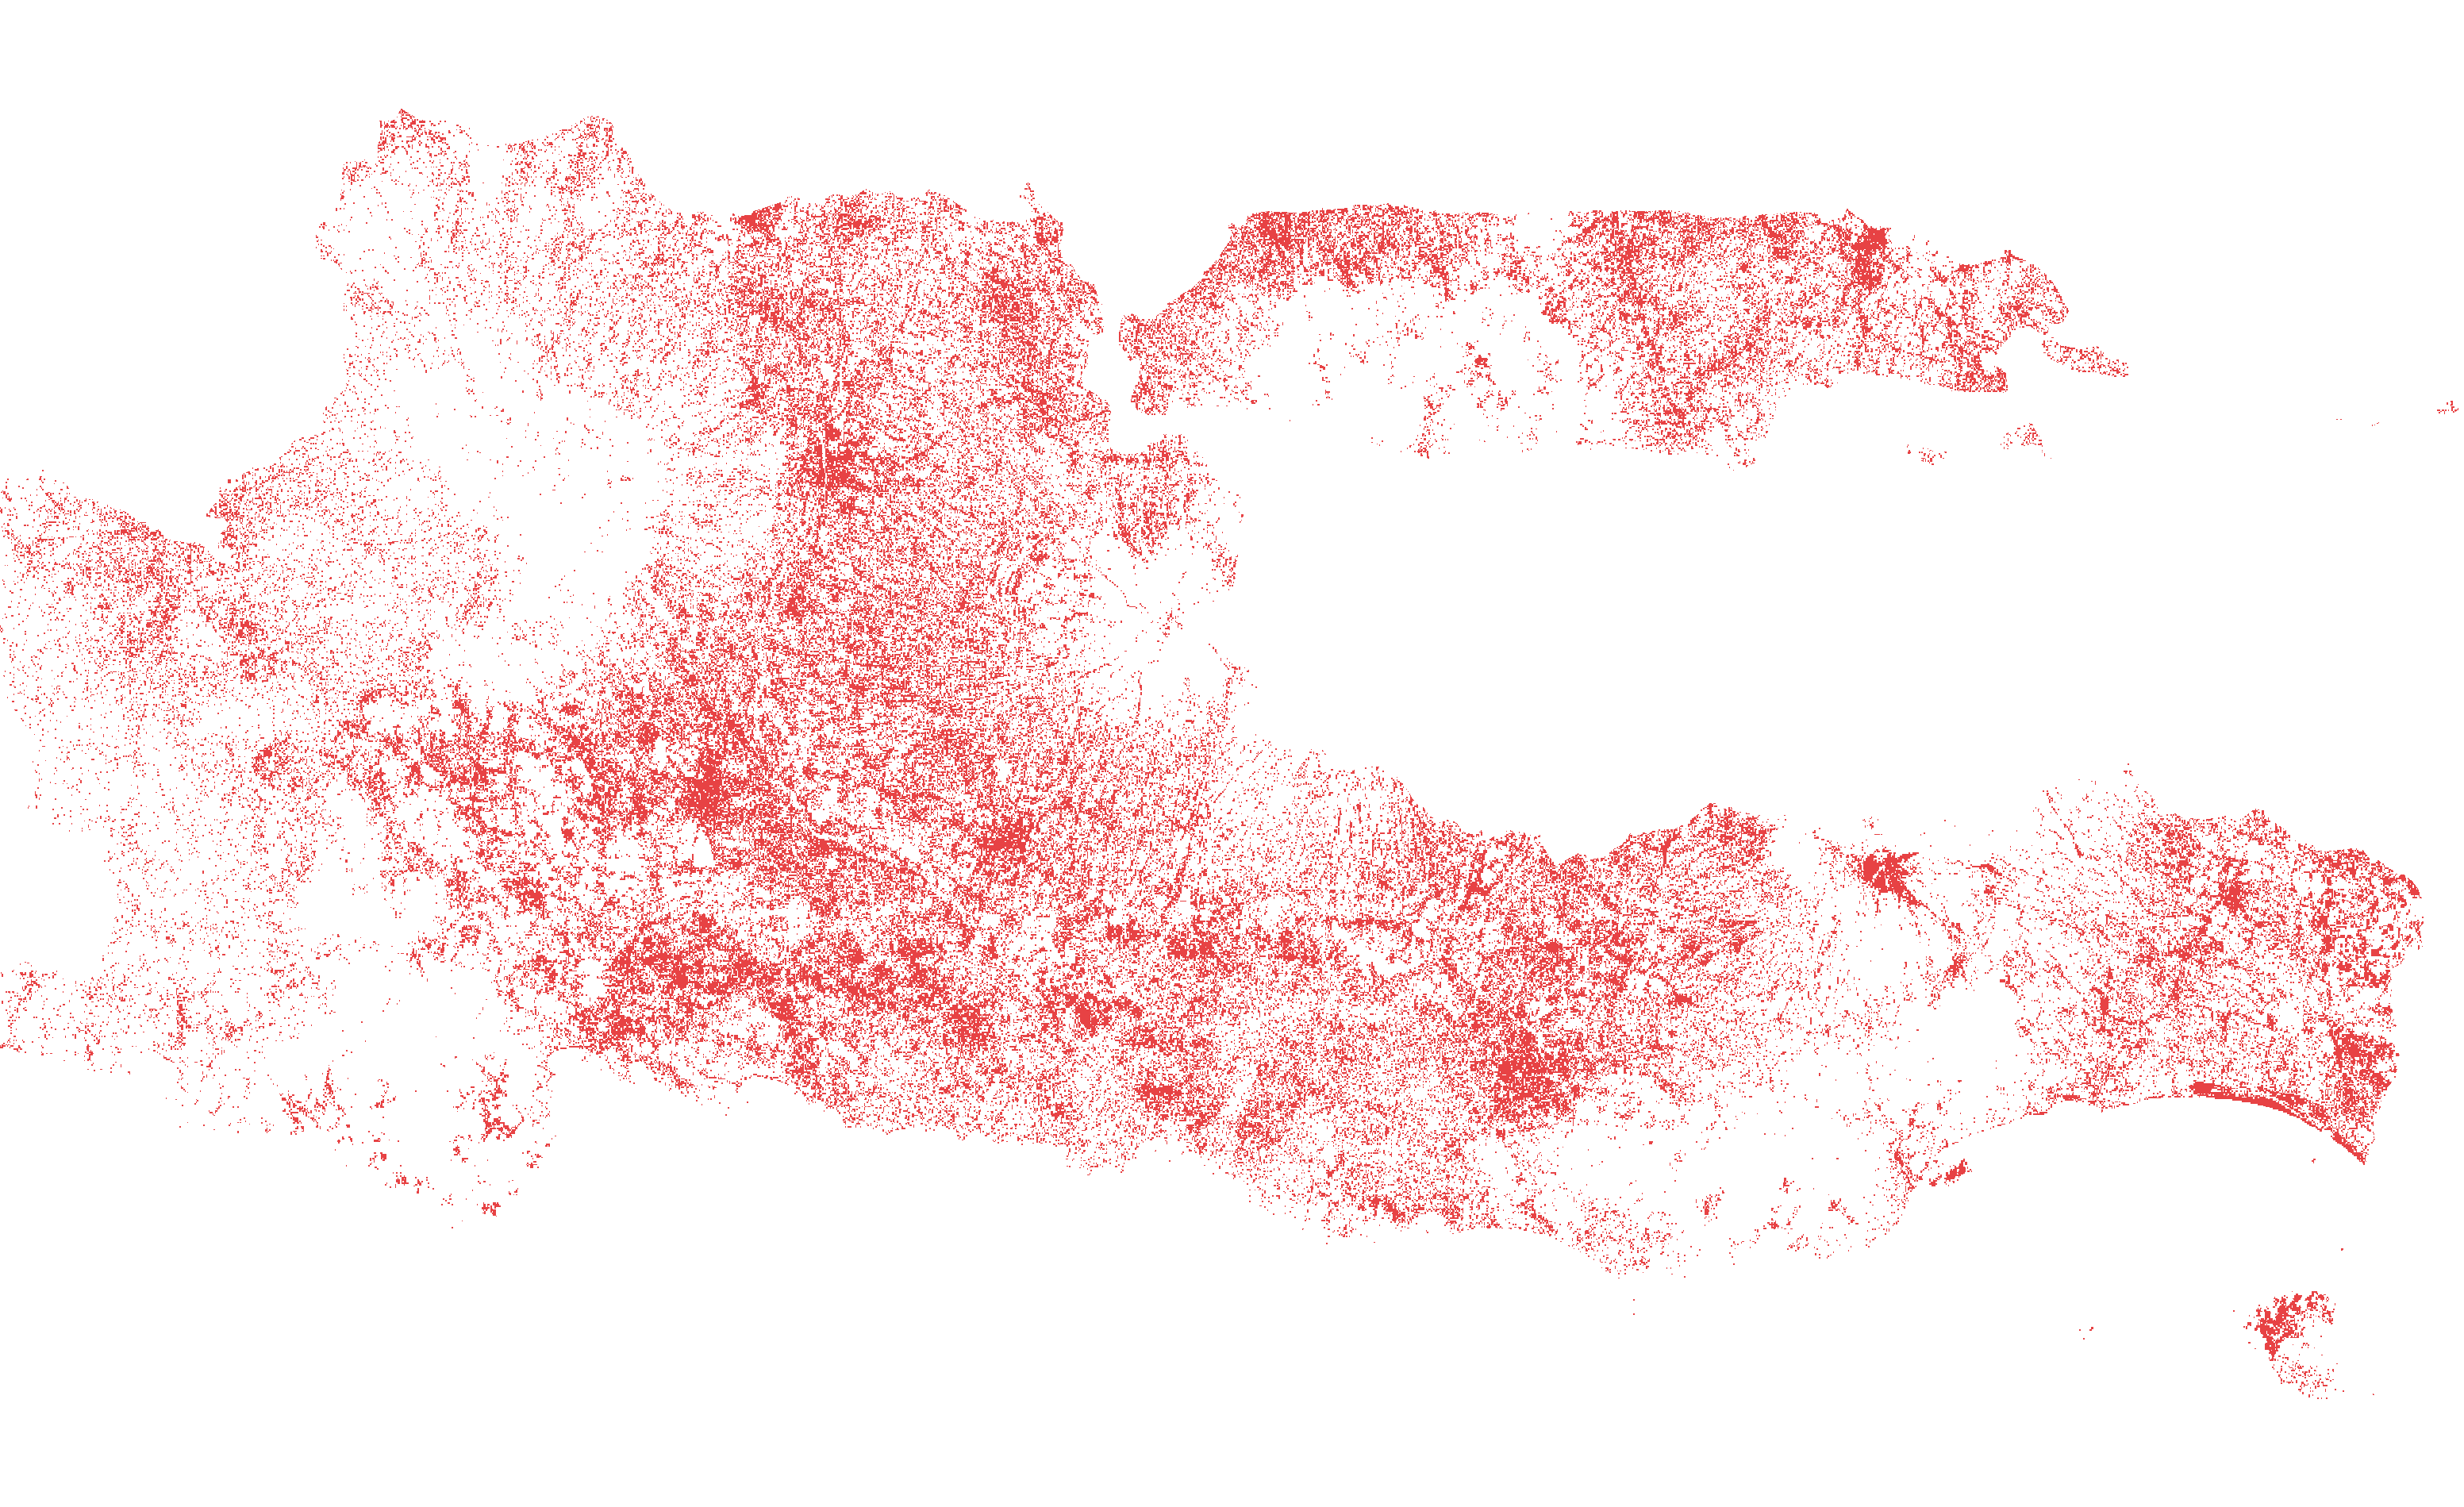
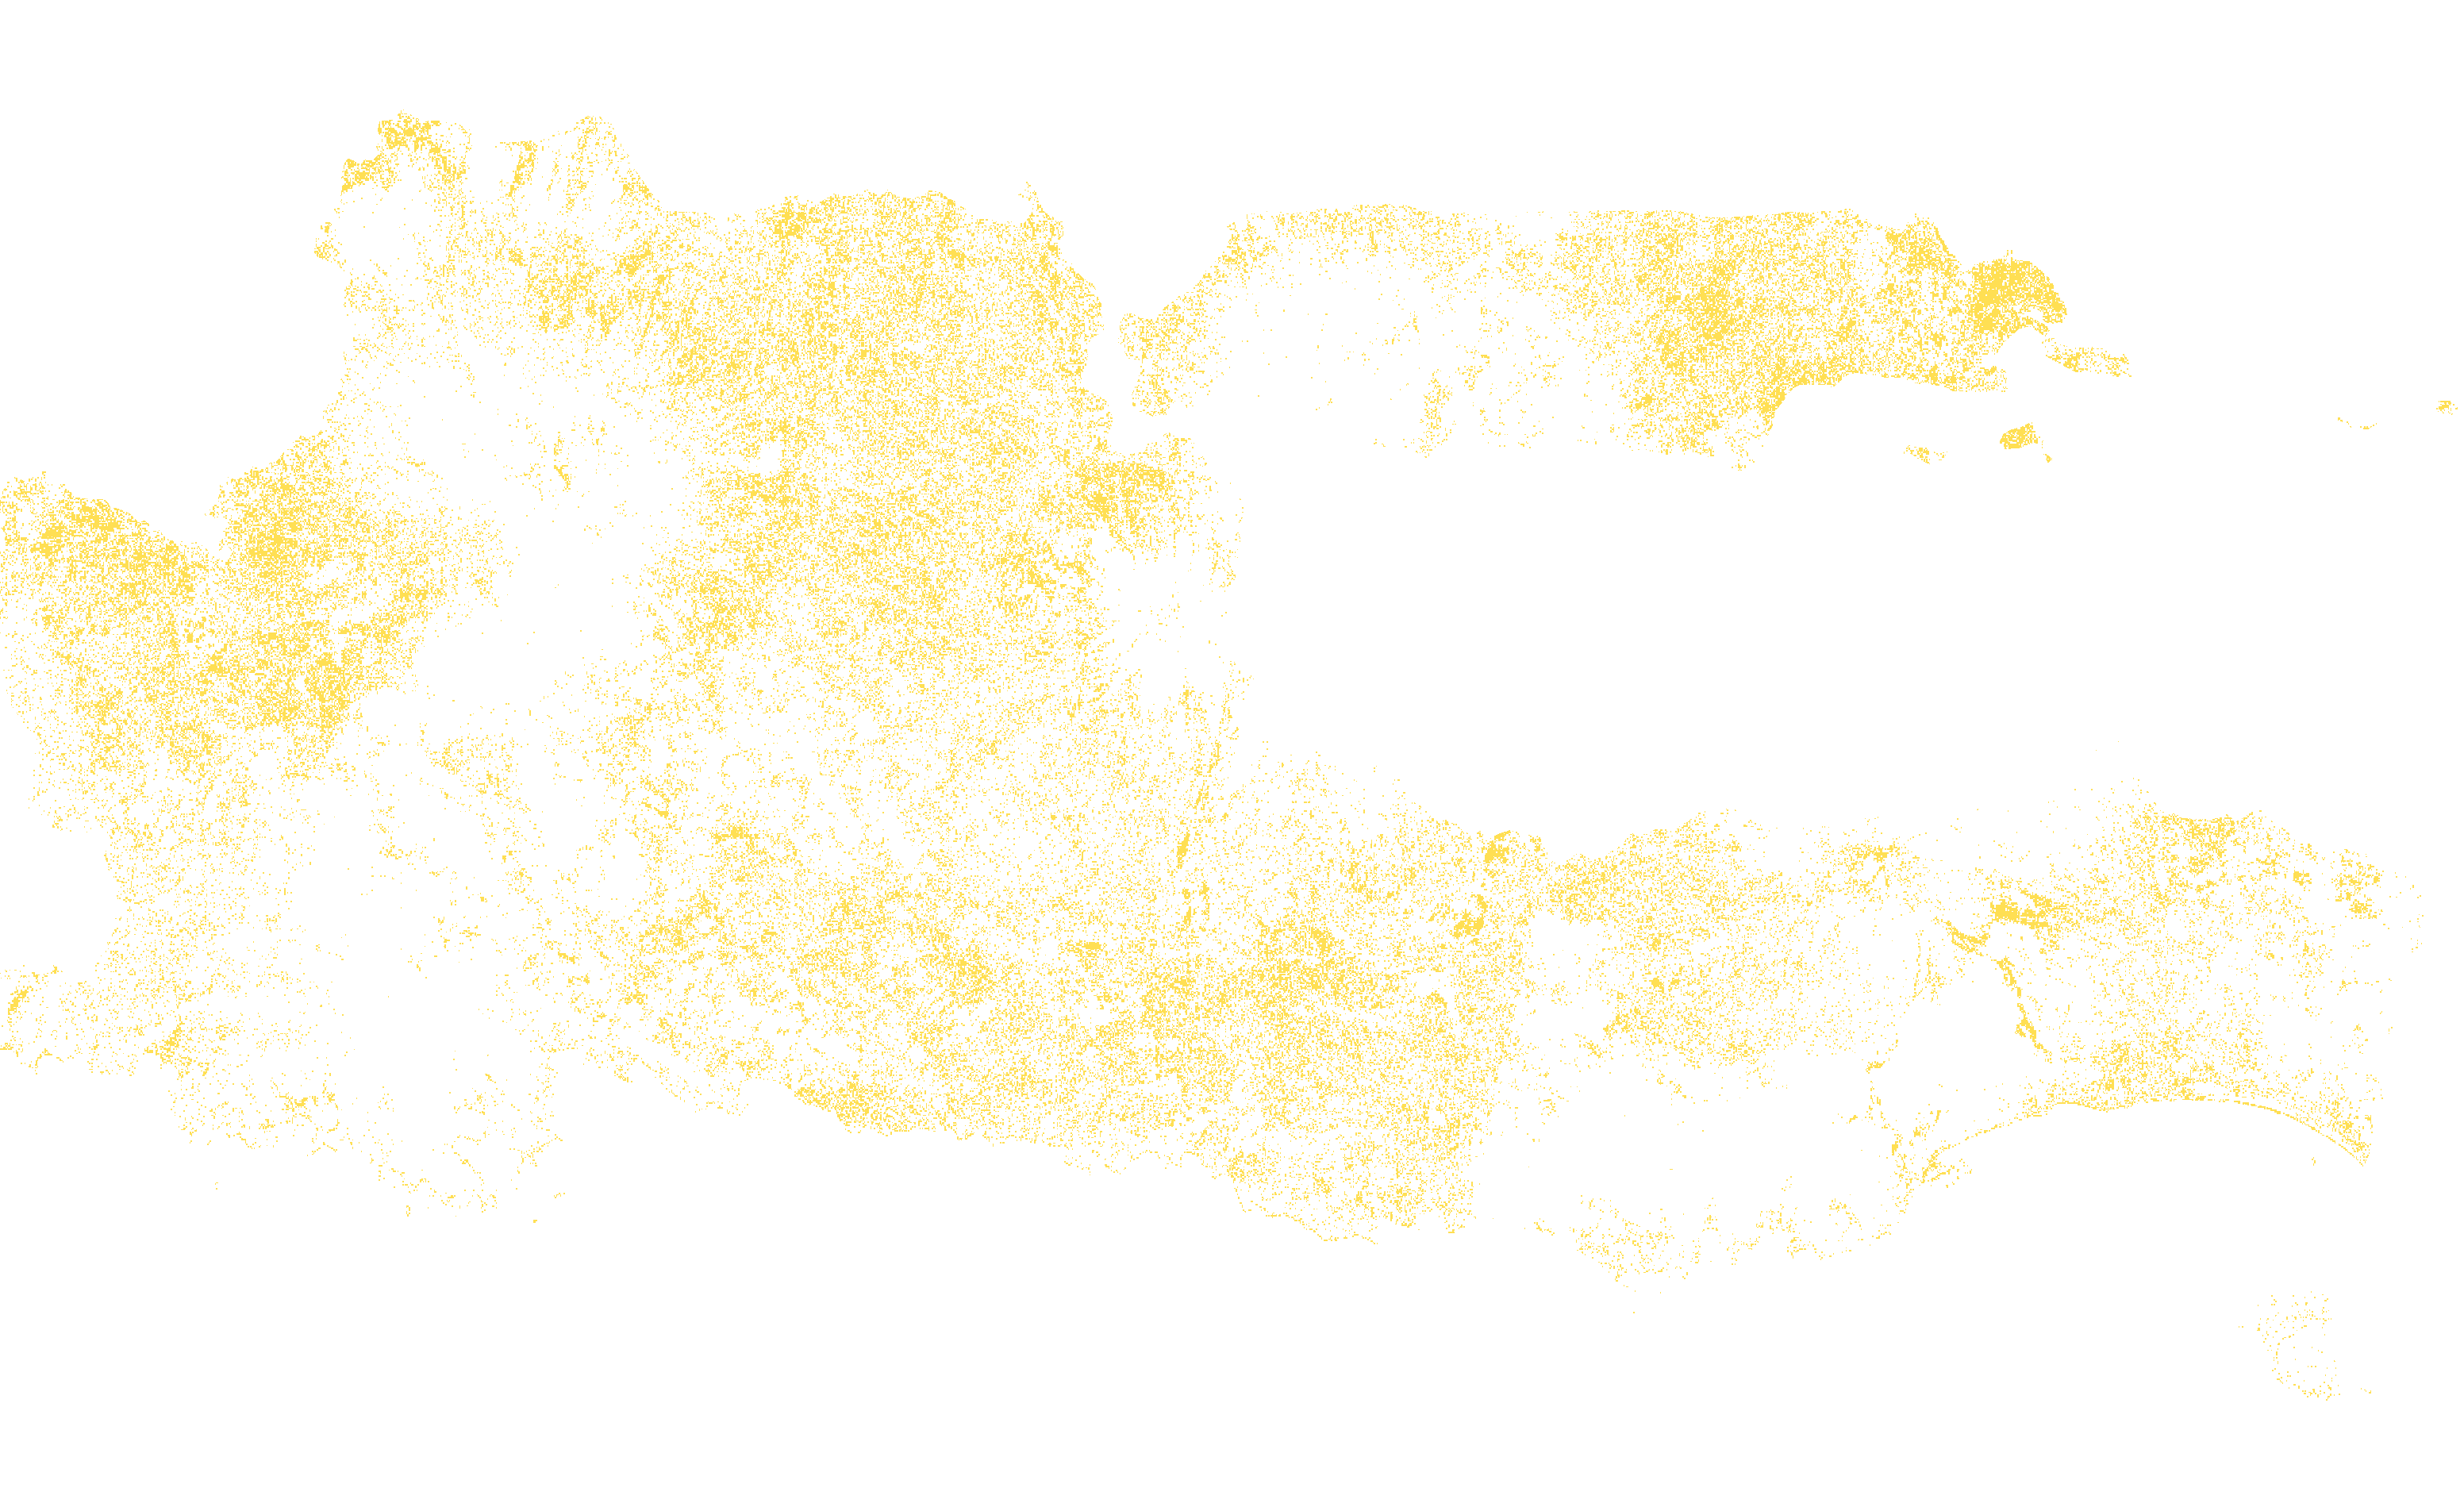
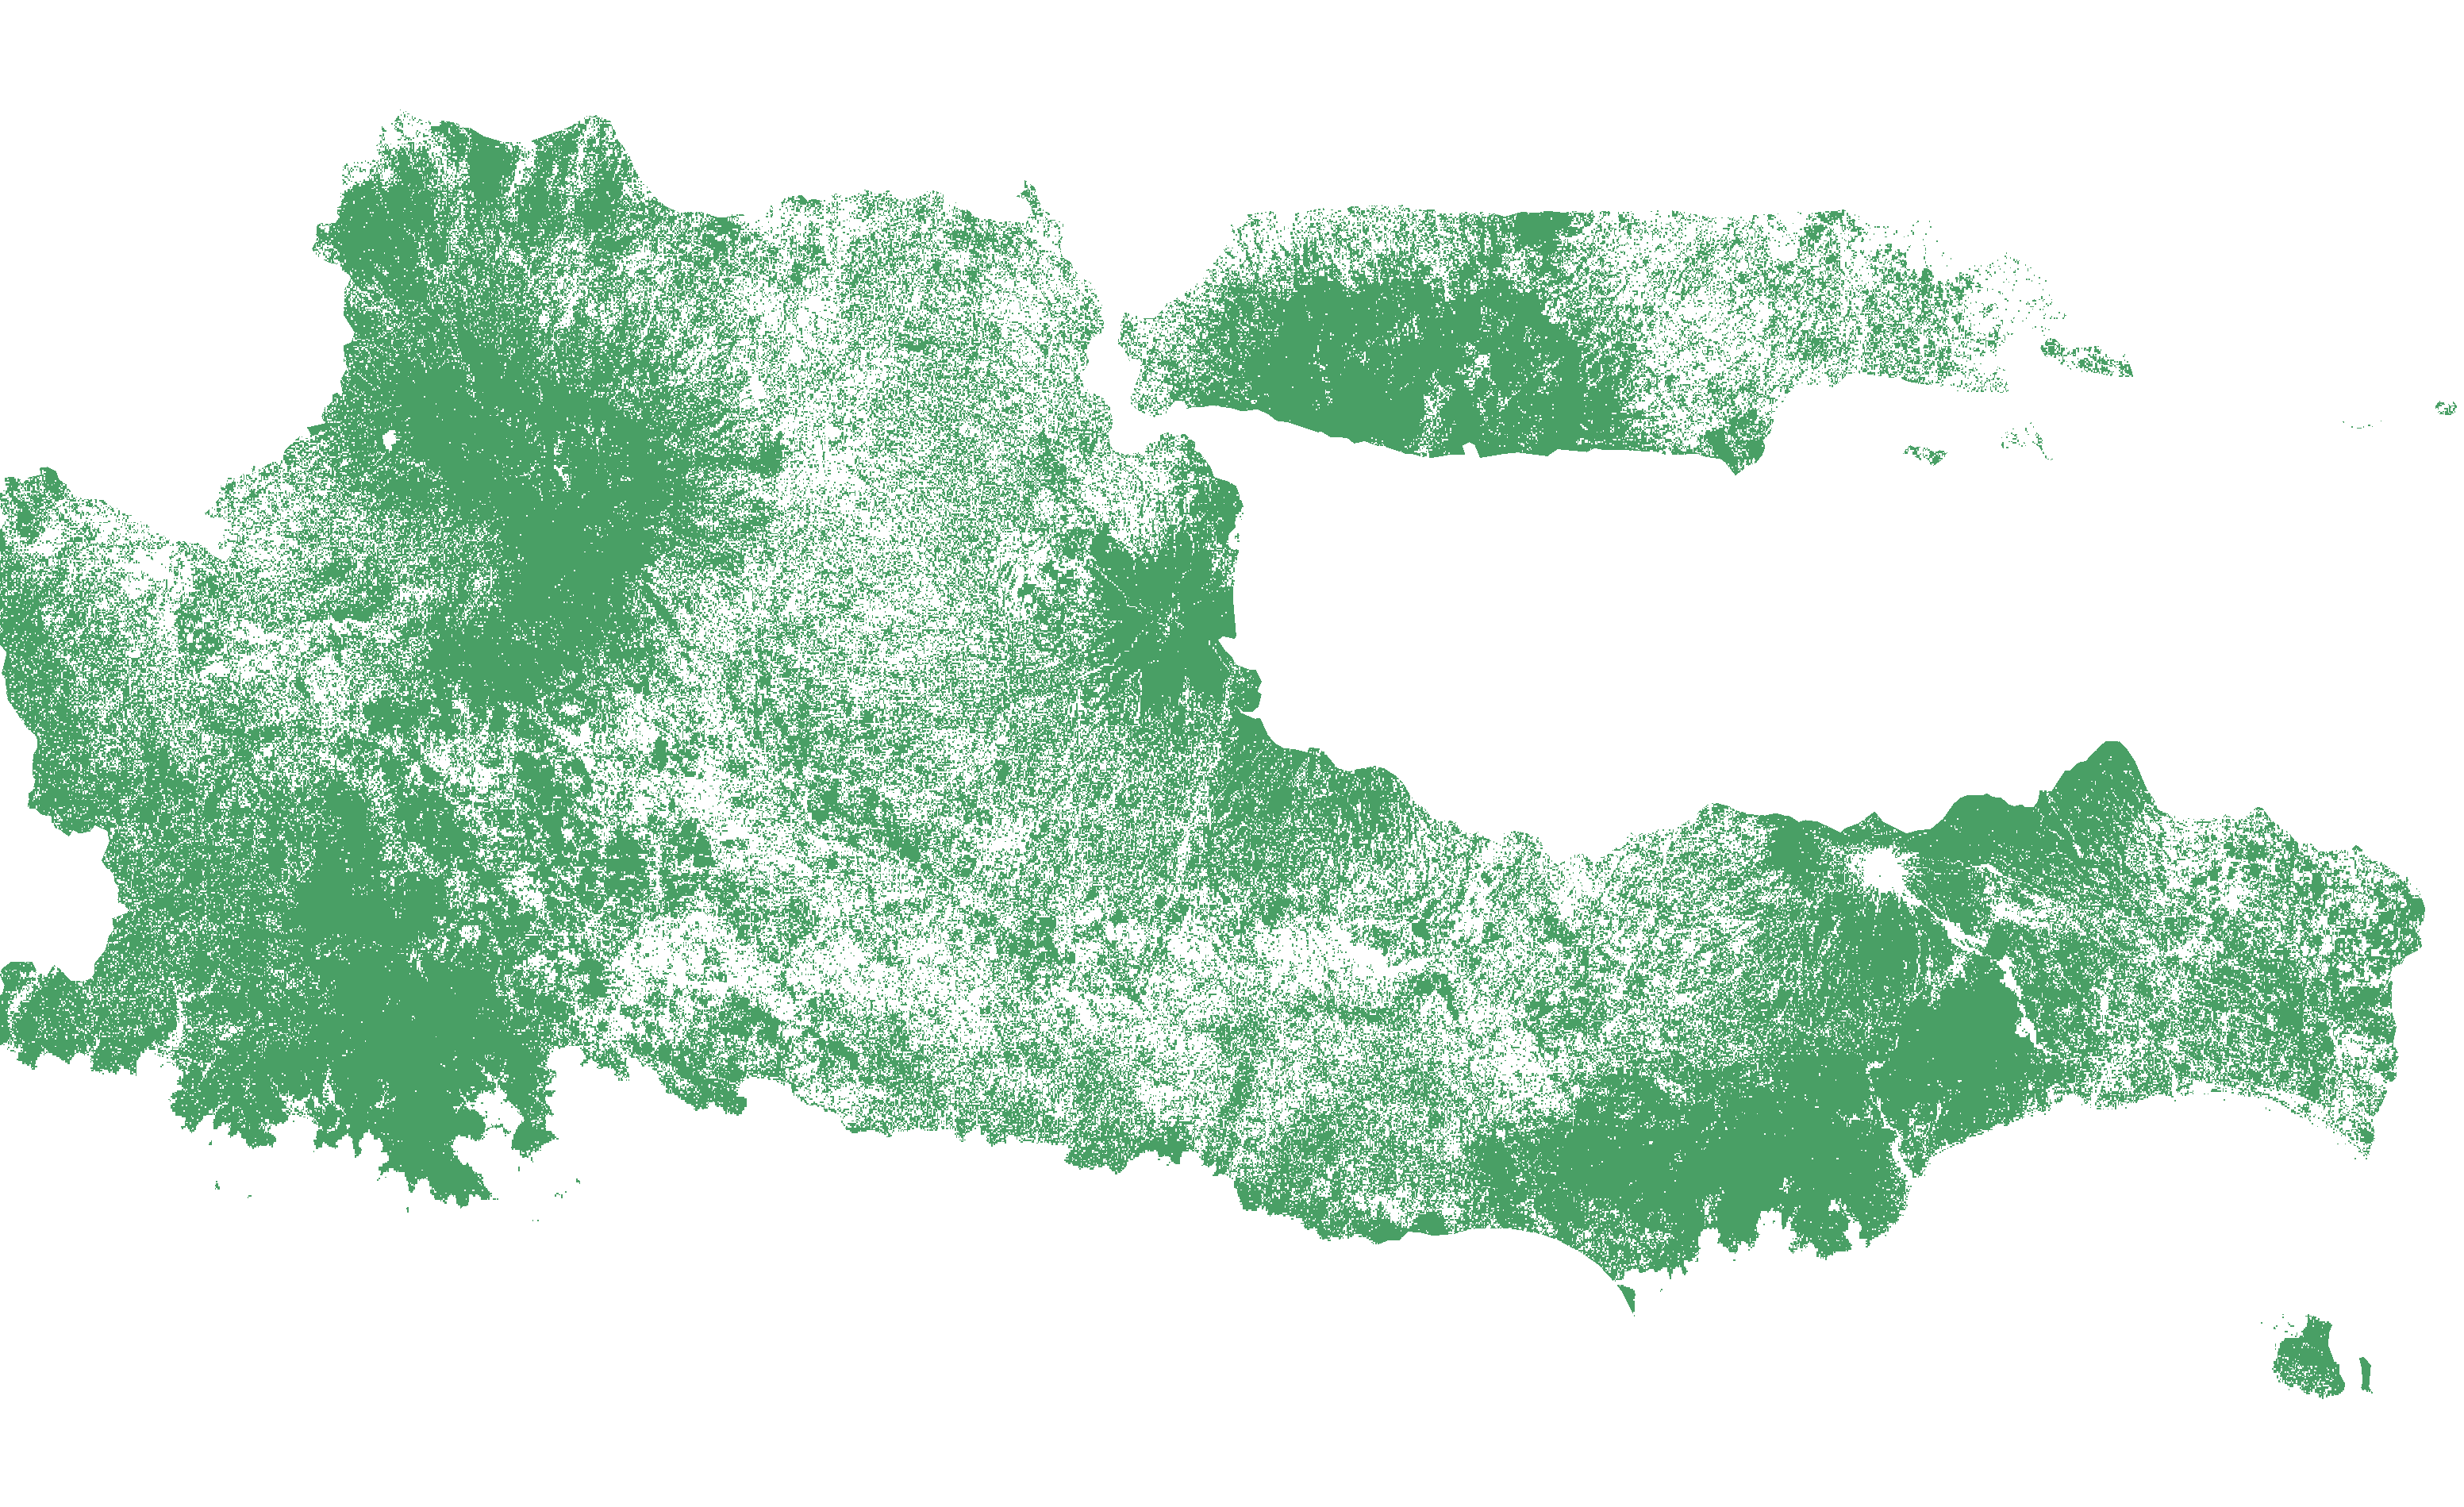
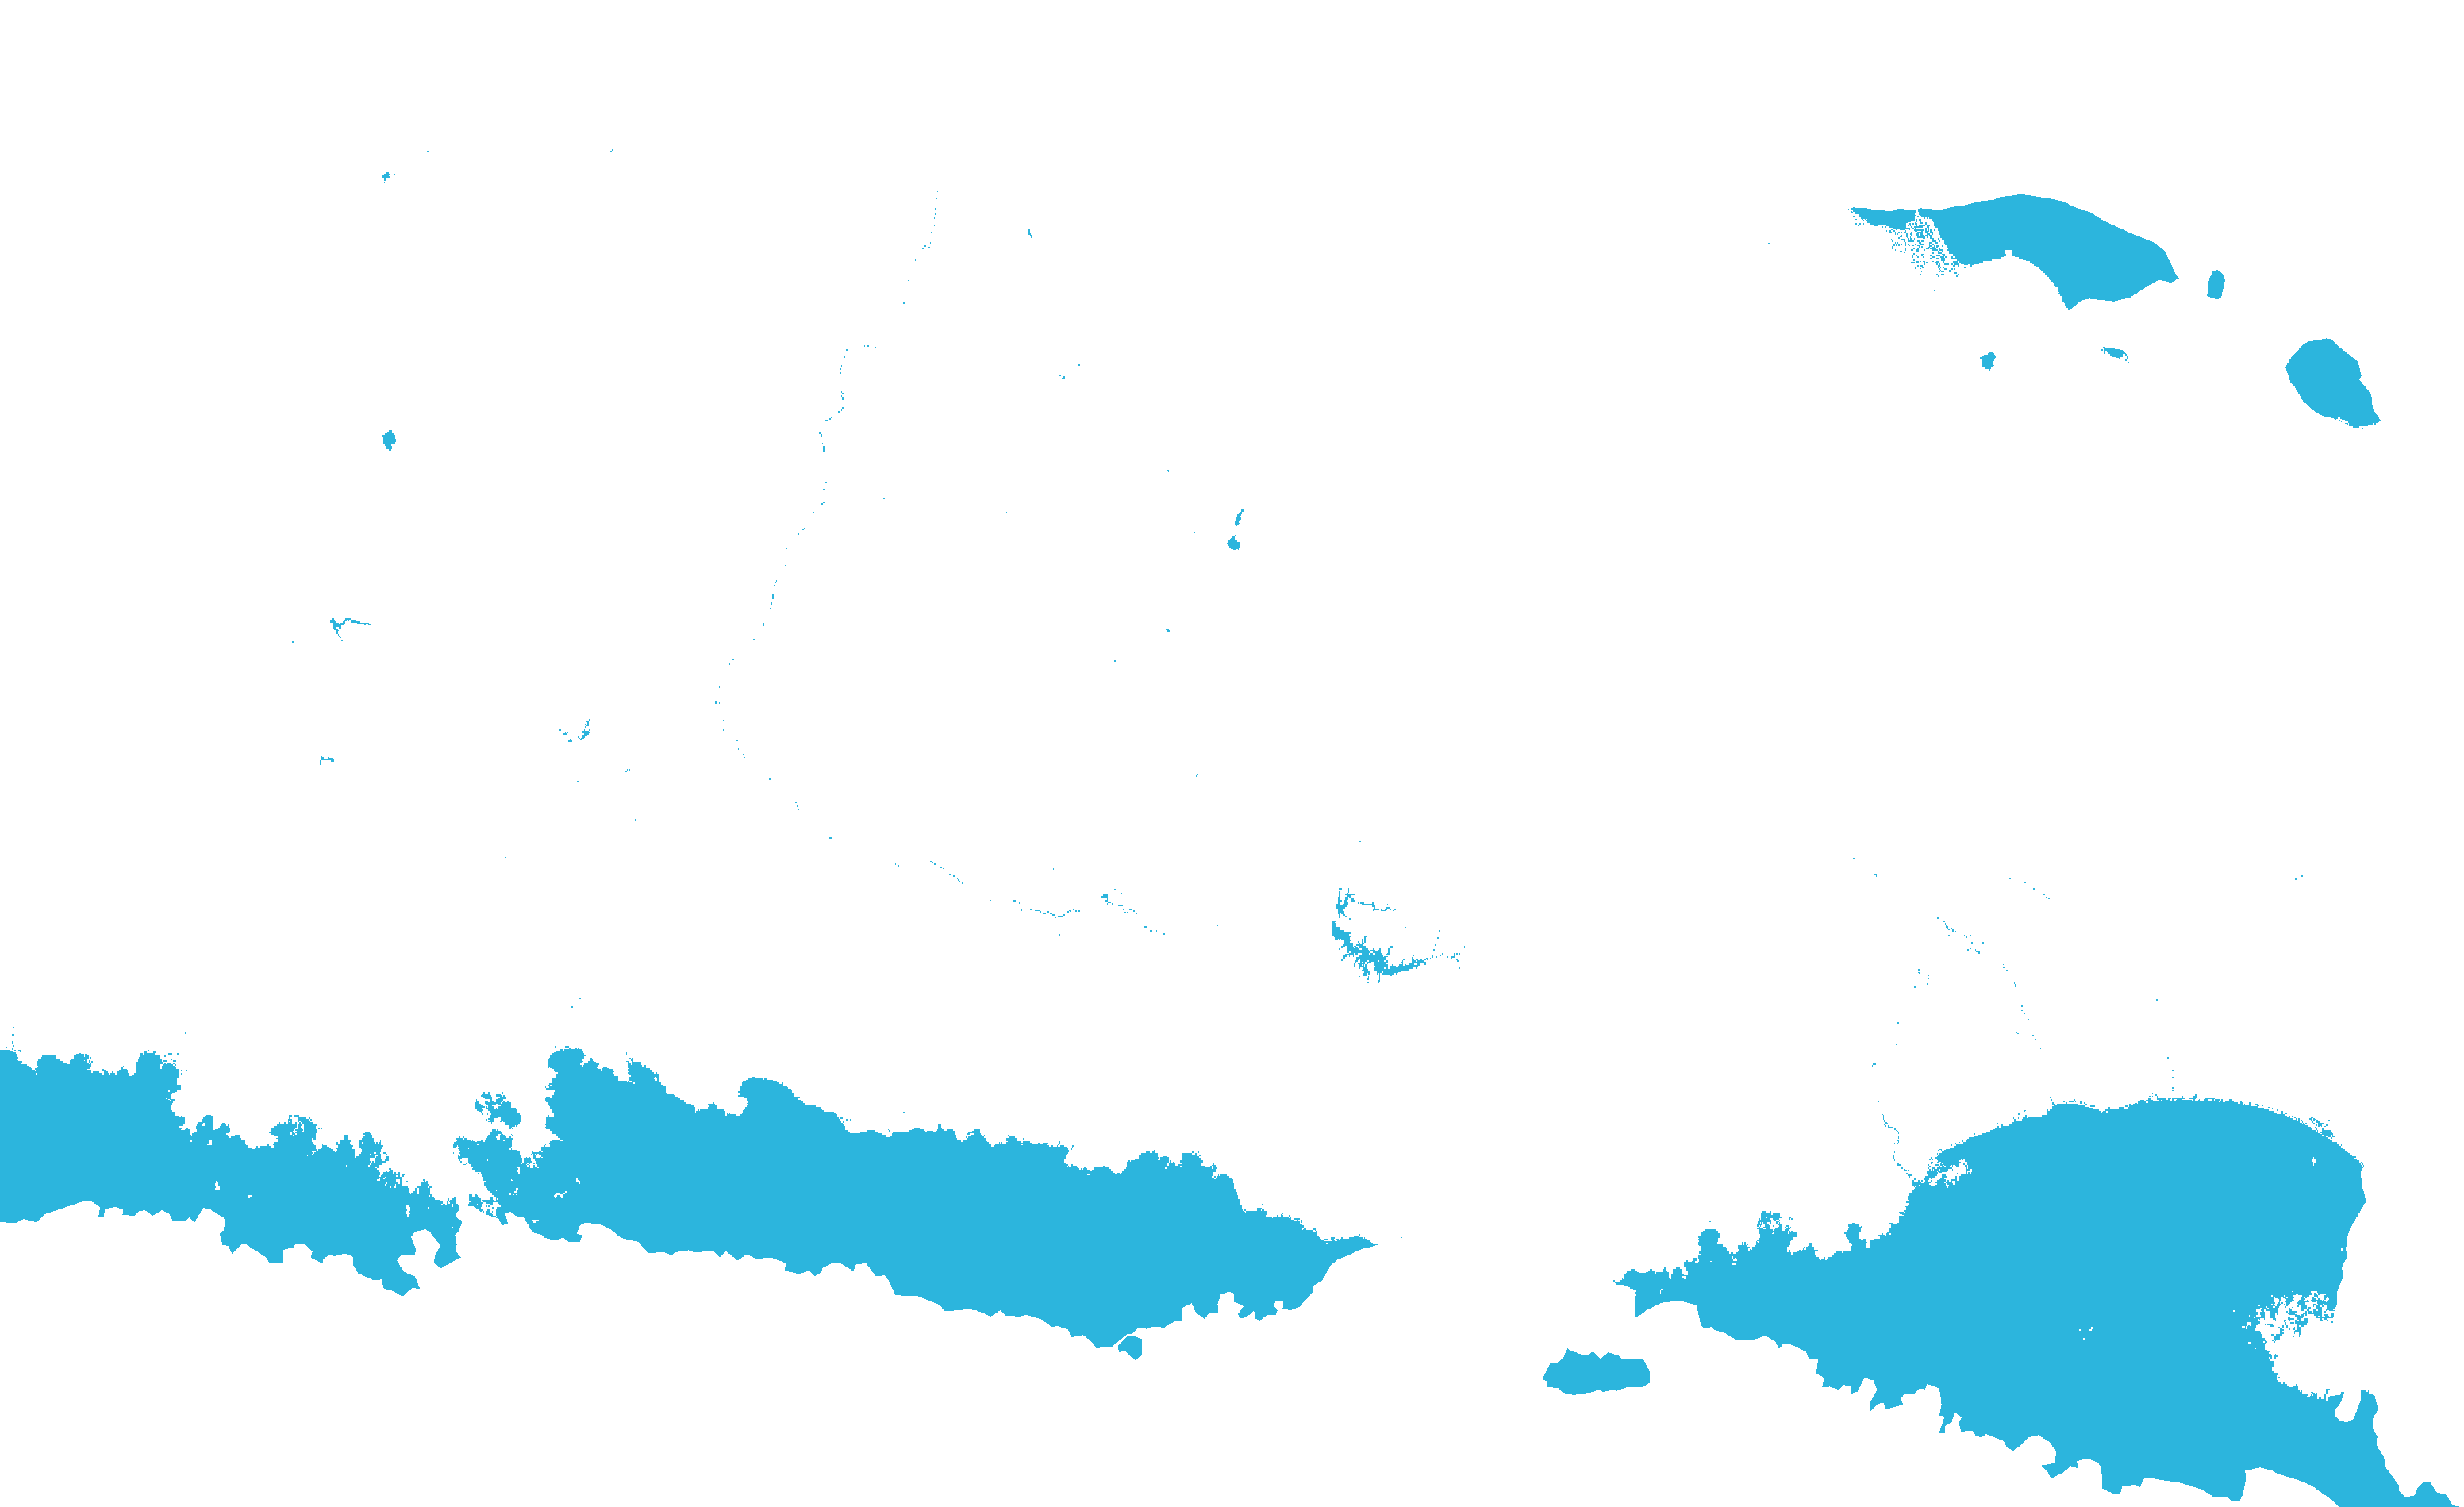
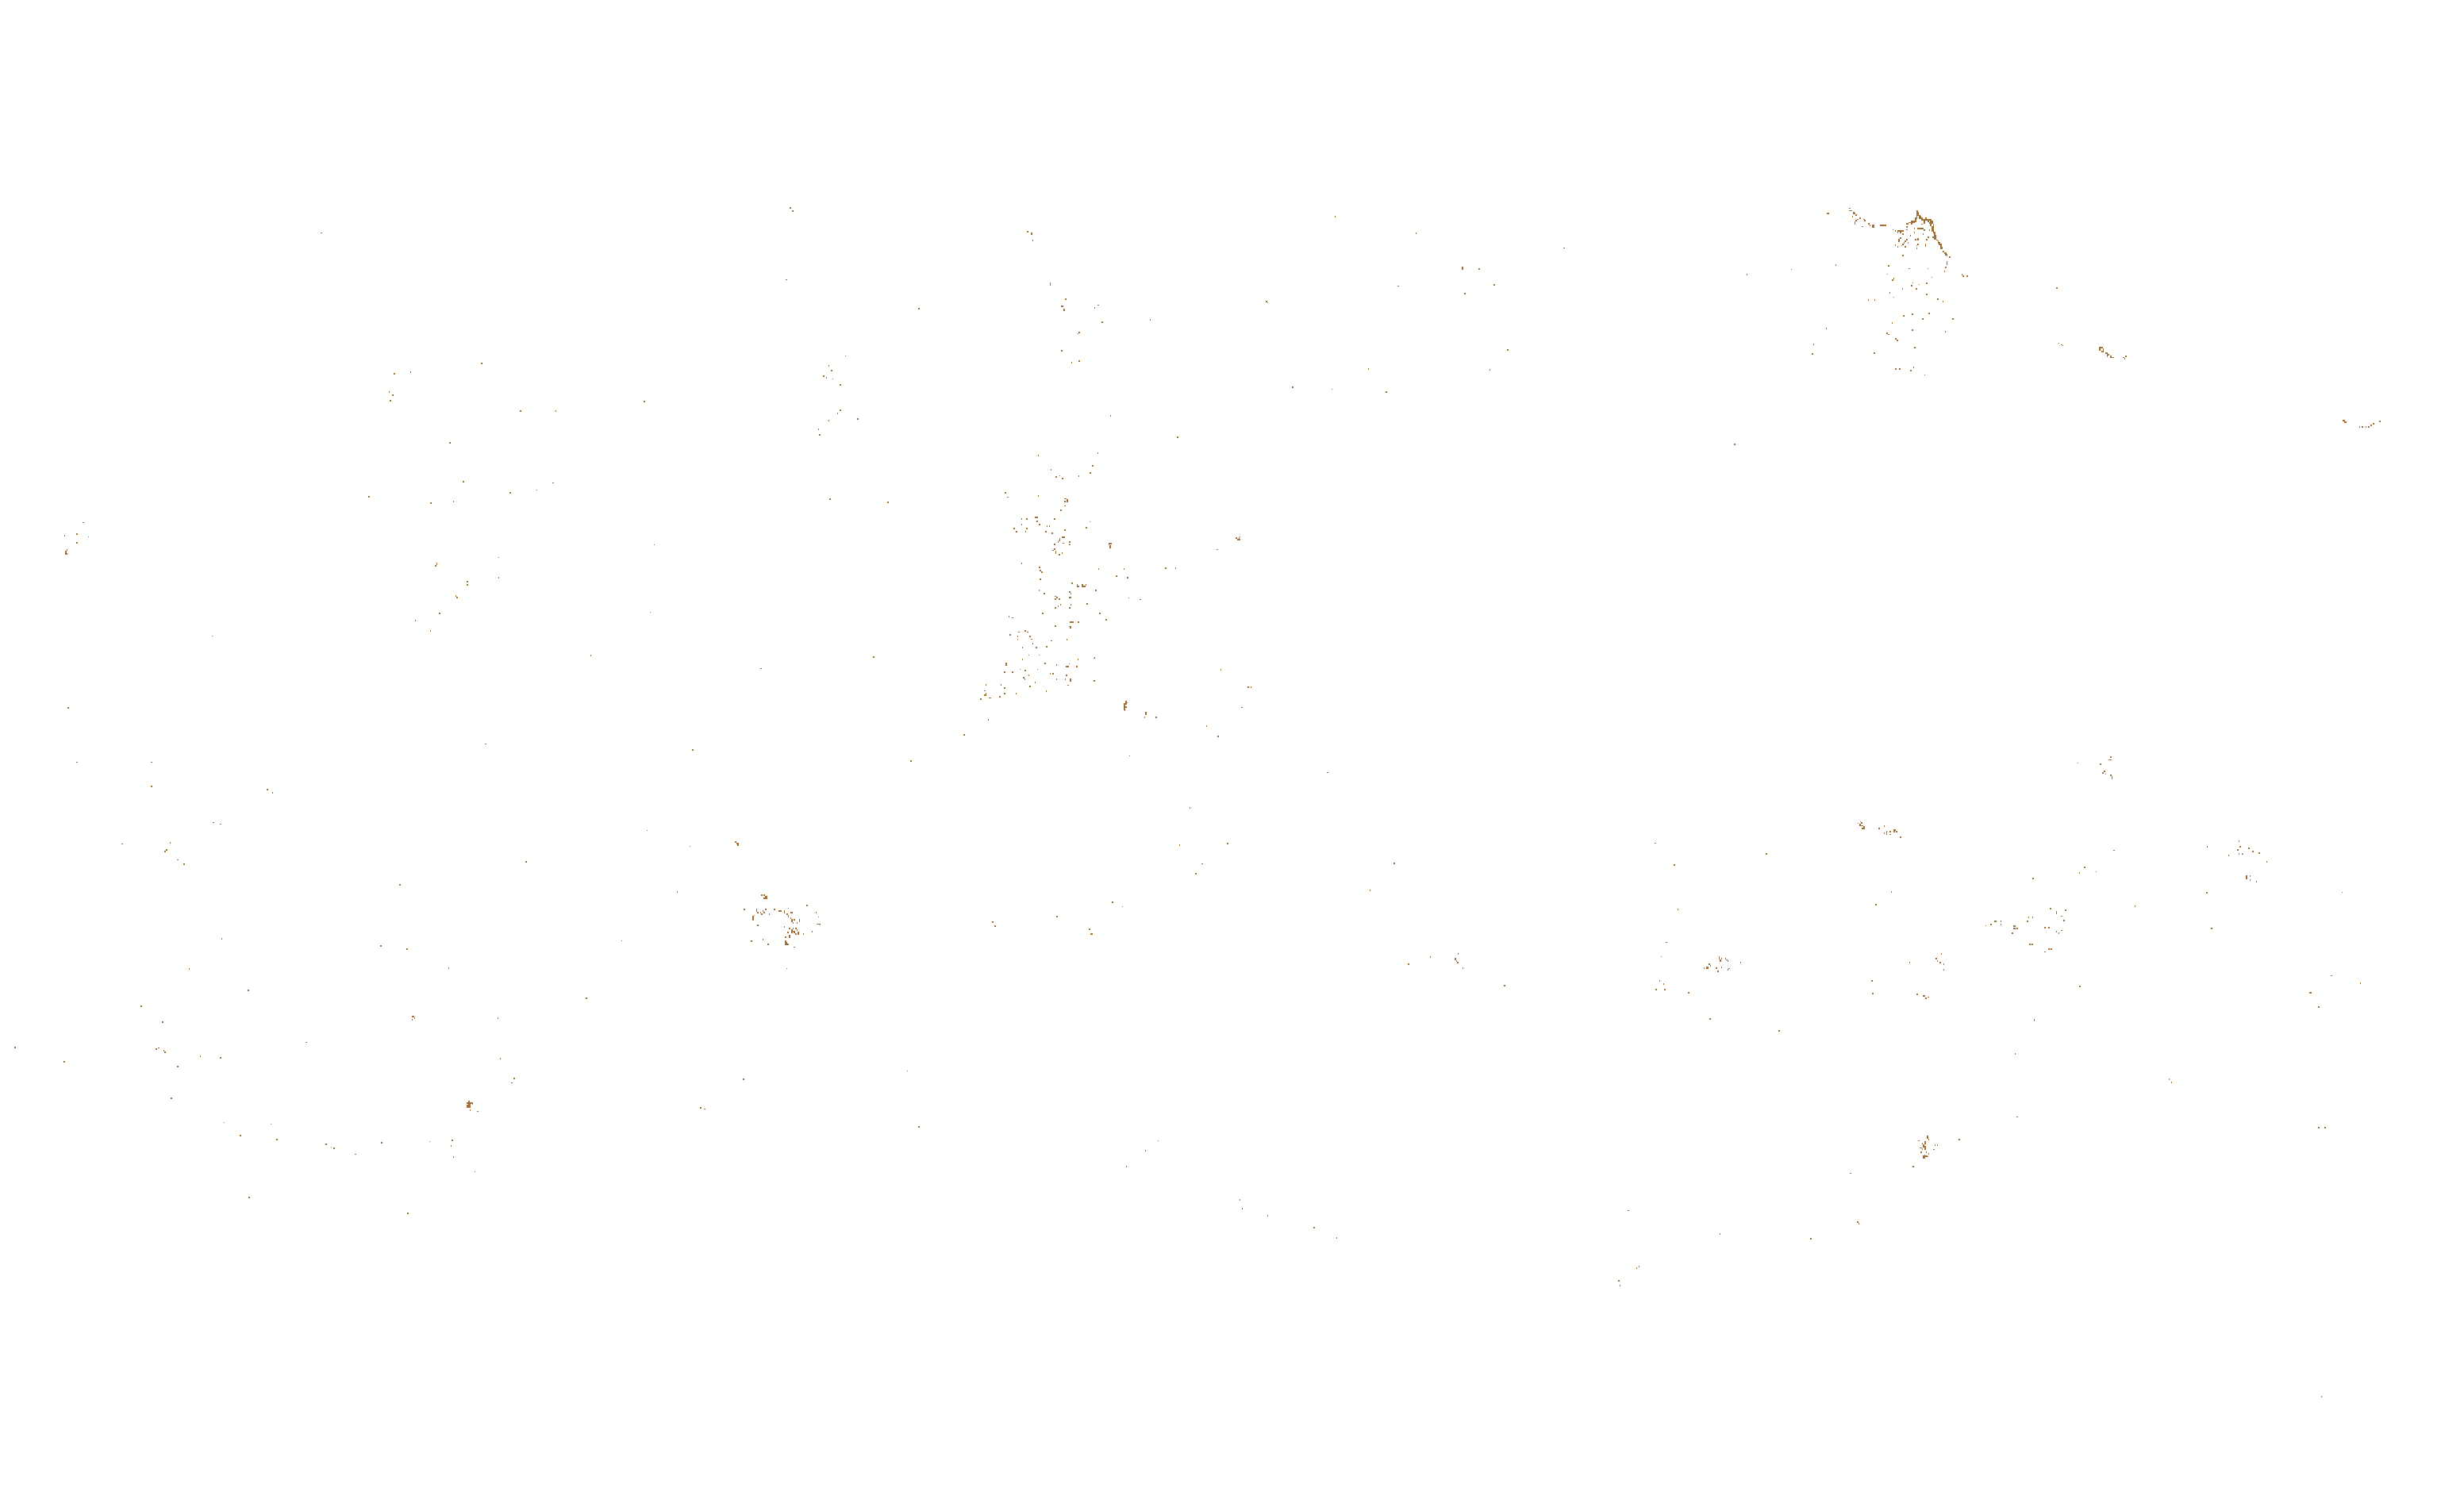

In [51]:
# ==============================================================================
# VISUALISASI PETA KLASIFIKASI TUTUPAN LAHAN JAWA TIMUR
# Random Forest - Menu Hasil Klasifikasi per Kelas
# ==============================================================================

import os
import numpy as np
import rasterio
import matplotlib.pyplot as plt
import folium
import geopandas as gpd

from rasterio.warp import transform_bounds
from folium.raster_layers import ImageOverlay
from folium.plugins import Fullscreen, FeatureGroupSubGroup

# ==============================================================================
# 1. PATH DATA
# ==============================================================================

DAFTAR_PATH_KLASIFIKASI = [
    "data/tif/hasil_klasifikasi_rf.tif",
    "../data/tif/hasil_klasifikasi_rf.tif",
    "uts/data/tif/hasil_klasifikasi_rf.tif"
]
PATH_KLASIFIKASI = next((p for p in DAFTAR_PATH_KLASIFIKASI if os.path.exists(p)), "data/tif/hasil_klasifikasi_rf.tif")

DAFTAR_PATH_SAMPEL = [
    "../data/geojson/build.geojson",
    "data/geojson/build.geojson"
]
PATH_SAMPEL = next((p for p in DAFTAR_PATH_SAMPEL if os.path.exists(p)), "../data/geojson/build.geojson")

DAFTAR_PATH_BATAS = [
    "../data/geojson/jawa_timur_provinsi.geojson",
    "data/geojson/jawa_timur_provinsi.geojson"
]
PATH_BATAS = next((p for p in DAFTAR_PATH_BATAS if os.path.exists(p)), "../data/geojson/jawa_timur_provinsi.geojson")

KOLOM_KELAS = "Type"

OUTPUT_DIR = "data/tif/hasil_per_kelas"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# ==============================================================================
# 2. WARNA DAN NAMA KELAS
# Selaras dengan kode kelas raster: 1=Bangunan, 2=Sawah, 3=Hutan, 4=Perairan, 5=Mangrove
# ==============================================================================

WARNA_KELAS = {
    1: ("Bangunan / Pemukiman", "#e31a1c"),
    2: ("Lahan Pertanian (Sawah)", "#ffd92f"),
    3: ("Hutan Biasa", "#238b45"),
    4: ("Perairan (Water Body)", "#00a6d6"),
    5: ("Hutan Mangrove", "#8c510a"),
}

WARNA_SAMPEL = {
    "pertanian": "#ffff00",
    "pemukiman": "#ff0000",
    "mangrove": "#8c510a",
    "hutan": "#00a000",
    "air": "#00bfff",
}

# ==============================================================================
# 3. BACA GEOJSON SAMPEL DAN BATAS PROVINSI
# ==============================================================================

gdf_sampel = gpd.read_file(PATH_SAMPEL)
gdf_batas = gpd.read_file(PATH_BATAS)

if gdf_sampel.crs is None:
    raise ValueError("CRS GeoJSON sampel tidak ditemukan.")

if gdf_batas.crs is None:
    raise ValueError("CRS GeoJSON batas provinsi tidak ditemukan.")

if KOLOM_KELAS not in gdf_sampel.columns:
    raise ValueError(
        f"Kolom '{KOLOM_KELAS}' tidak ditemukan. "
        f"Kolom tersedia: {gdf_sampel.columns.tolist()}"
    )

# Ubah CRS untuk visualisasi Folium
gdf_sampel = gdf_sampel.to_crs("EPSG:4326")
gdf_batas = gdf_batas.to_crs("EPSG:4326")

print("Jumlah sampel:", len(gdf_sampel))
print("\nDistribusi kelas sampel:")
print(gdf_sampel[KOLOM_KELAS].value_counts())

# ==============================================================================
# 4. BACA RASTER HASIL KLASIFIKASI
# ==============================================================================

with rasterio.open(PATH_KLASIFIKASI) as src:
    hasil = src.read(1)
    nodata = src.nodata
    crs_raster = src.crs

    # Menampilkan seluruh hasil klasifikasi termasuk area laut / perairan terbuka
    hasil_tampil = hasil.copy()

    # Batas raster ke koordinat geografis untuk Folium
    bounds = transform_bounds(
        crs_raster,
        "EPSG:4326",
        *src.bounds
    )

    bounds_folium = [
        [bounds[1], bounds[0]],
        [bounds[3], bounds[2]]
    ]

# ==============================================================================
# 5. BUAT PETA DASAR
# ==============================================================================

minx, miny, maxx, maxy = gdf_batas.total_bounds
pusat = [
    (miny + maxy) / 2,
    (minx + maxx) / 2
]

m = folium.Map(
    location=pusat,
    zoom_start=8,
    tiles=None
)

# Citra satelit
folium.TileLayer(
    tiles=(
        "https://server.arcgisonline.com/ArcGIS/rest/services/"
        "World_Imagery/MapServer/tile/{z}/{y}/{x}"
    ),
    attr="Esri",
    name="Citra Satelit (Esri)",
    overlay=False
).add_to(m)

# Google Hybrid
folium.TileLayer(
    tiles="https://mt1.google.com/vt/lyrs=y&x={x}&y={y}&z={z}",
    attr="Google",
    name="Google Hybrid",
    overlay=False
).add_to(m)

# ==============================================================================
# 6. GRUP UTAMA HASIL KLASIFIKASI
# ==============================================================================

grup_klasifikasi = folium.FeatureGroup(
    name="Hasil Klasifikasi",
    show=True
).add_to(m)

# ==============================================================================
# 7. BUAT LAYER TERPISAH UNTUK SETIAP KELAS
# ==============================================================================

for kode, (nama_kelas, hex_warna) in WARNA_KELAS.items():

    # Mask khusus kelas yang sedang diproses
    mask = hasil_tampil == kode

    # Siapkan gambar RGBA transparan
    warna = np.zeros(
        (hasil_tampil.shape[0], hasil_tampil.shape[1], 4),
        dtype=np.uint8
    )

    # Ubah HEX menjadi RGB
    hex_bersih = hex_warna.lstrip("#")
    rgb = tuple(
        int(hex_bersih[i:i + 2], 16)
        for i in (0, 2, 4)
    )

    # Beri warna hanya untuk kelas terpilih
    warna[mask, 0] = rgb[0]
    warna[mask, 1] = rgb[1]
    warna[mask, 2] = rgb[2]
    warna[mask, 3] = 210

    # Simpan PNG untuk kelas ini
    nama_file = (
        nama_kelas.lower()
        .replace(" / ", "_")
        .replace(" ", "_")
        .replace("(", "")
        .replace(")", "")
    )

    path_png = os.path.join(
        OUTPUT_DIR,
        f"kelas_{kode}_{nama_file}.png"
    )

    plt.imsave(path_png, warna)

    # Buat submenu kelas di bawah grup klasifikasi
    subgrup = FeatureGroupSubGroup(
        grup_klasifikasi,
        name=nama_kelas,
        show=False
    )
    subgrup.add_to(m)

    # Tambahkan overlay ke submenu
    ImageOverlay(
        image=path_png,
        bounds=bounds_folium,
        name=nama_kelas,
        opacity=0.9
    ).add_to(subgrup)

    print(
        f"{nama_kelas}: {int(mask.sum()):,} piksel"
    )

# ==============================================================================
# 8. LAYER SAMPEL GEOJSON PER KELAS
# ==============================================================================

gdf_sampel["_kelas_normalisasi"] = (
    gdf_sampel[KOLOM_KELAS]
    .astype(str)
    .str.strip()
    .str.lower()
)

for kelas, warna_sampel in WARNA_SAMPEL.items():

    layer_sampel = folium.FeatureGroup(
        name=f"Sampel: {kelas.title()}",
        show=False
    )

    data_kelas = gdf_sampel[
        gdf_sampel["_kelas_normalisasi"] == kelas.lower()
    ].copy()

    if not data_kelas.empty:
        folium.GeoJson(
            data_kelas,
            style_function=lambda feature, c=warna_sampel: {
                "color": c,
                "fillColor": c,
                "weight": 2,
                "fillOpacity": 0.35
            },
            tooltip=folium.GeoJsonTooltip(
                fields=[KOLOM_KELAS],
                aliases=["Kelas:"]
            )
        ).add_to(layer_sampel)

    layer_sampel.add_to(m)

# ==============================================================================
# 9. BATAS PROVINSI JAWA TIMUR
# ==============================================================================

folium.GeoJson(
    gdf_batas,
    name="Batas Provinsi Jawa Timur",
    style_function=lambda feature: {
        "color": "white",
        "weight": 2,
        "fillOpacity": 0
    }
).add_to(m)

# ==============================================================================
# 10. KONTROL LAYER DAN FULLSCREEN
# ==============================================================================

folium.LayerControl(
    collapsed=False
).add_to(m)

Fullscreen(
    position="topleft",
    title="Layar penuh",
    title_cancel="Keluar layar penuh",
    force_separate_button=True
).add_to(m)

m.fit_bounds([
    [miny, minx],
    [maxy, maxx]
])

# ==============================================================================
# 11. SIMPAN PETA
# ==============================================================================

OUTPUT_HTML = "peta_klasifikasi_tutupan_lahan_jatim2.html"
m.save(OUTPUT_HTML)
m.save("peta_klasifikasi_tutupan_lahan_jatim.html")

print("\nPeta berhasil disimpan:")
print(os.path.abspath(OUTPUT_HTML))

print("\nGambar per kelas tersimpan di:")
print(os.path.abspath(OUTPUT_DIR))

# Tampilkan peta di Jupyter Notebook
m


# 10. Kesimpulan dan Rekomendasi Proyek

Berdasarkan seluruh tahapan implementasi sains data geospasial yang telah dilaksanakan pada proyek **Klasifikasi Tutupan Lahan Provinsi Jawa Timur**, dapat ditarik beberapa poin kesimpulan dan rekomendasi strategis:

---

### 1. Kinerja dan Keandalan Model Klasifikasi
- **Akurasi Model Tinggi:** Model **Random Forest Classifier** (dengan 200 *decision trees* dan *class weight balanced*) berhasil mencapai **Akurasi 90.00% pada tingkat piksel data uji** dan **Akurasi 76.09% pada tingkat evaluasi voting mayoritas poligon**.
- **Isolasi Spasial Bebas Kebocoran:** Evaluasi model dilakukan pada 46 poligon uji (8.996 piksel) yang sama sekali tidak dilibatkan dalam proses pelatihan (*Polygon-Based Stratified Split*). Hal ini membuktikan bahwa model memiliki kemampuan generalisasi yang kuat (*robust*) dan tidak sekadar menghafal poligon sampel (*spatial data leakage*).
- **Stabilitas Kelas Vegetasi:** Kelas **Hutan Biasa** (Precision 0.95, Recall 0.95, F1-Score 0.95) dan **Hutan Mangrove** (Precision 0.98, Recall 0.82, F1-Score 0.89) memiliki tingkat akurasi tertinggi, membuktikan keandalan fitur spektral optik dalam mengenali bioma vegetasi alami.

---

### 2. Signifikansi Rekayasa Fitur Spektral
- Dari 10 fitur masukan yang digunakan, fitur **indeks turunan matematis** mendominasi kontribusi penentuan kelas (*Feature Importance*):
  1. **Ratio B8A / B11 (14.27%):** Menjadi pembeda utama antara formasi hutan daratan biasa dengan hutan mangrove pesisir yang dipengaruhi genangan air payau berlumpur.
  2. **MNDWI (13.44%):** Sangat efektif memisahkan badan air terbuka dari area terbangun dan vegetasi.
  3. **NDVI (12.78%):** Parameter fundamental untuk mengukur kerapatan tajuk klorofil.
  4. **Band B02 / Biru (12.63%):** Sangat sensitif terhadap hamburan radiasi air dan pantulan material perkotaan.
- Rekayasa fitur spektral terbukti melipatgandakan daya pisah spektral (*spectral separability*) dibandingkan hanya mengandalkan nilai band mentah citra satelit.

---

### 3. Karakteristik Pola Spasial Jawa Timur
- Peta tutupan lahan hasil klasifikasi raster penuh se-Jawa Timur berhasil menggambarkan sebaran bentang alam secara realistis:
  - **Pemukiman (Merah):** Terkonsentrasi padat di wilayah metropolitan Surabaya Raya, Malang Raya, Sidoarjo, Gresik, serta sepanjang koridor arteri pantura dan jalan nasional.
  - **Lahan Pertanian/Sawah (Kuning):** Mendominasi dataran aluvial subur di Daerah Aliran Sungai (DAS) Bengawan Solo dan DAS Brantas (Bojonegoro, Lamongan, Ngawi, Nganjuk, Jombang).
  - **Hutan Biasa (Hijau):** Terdistribusi kokoh di kawasan pegunungan vulkanik tengah dan selatan (TN Bromo Tengger Semeru, Arjuno-Welirang, Raung-Ijen).
  - **Hutan Mangrove (Ungu):** Terpetakan presisi di zona pasang-surut pesisir pantai utara (Ujung Pangkah Gresik, Surabaya Timur) dan pesisir teluk selatan.
  - **Perairan (Biru):** Menandai waduk-waduk strategis (Karangkates, Selorejo, Sutami), danau alami, dan sungai utama.

---

### 4. Tantangan Analisis dan Batasan
- **Ambiguitas Musiman Sawah:** Tantangan klasifikasi terbesar berada pada pemisahan antara **Lahan Pertanian (Sawah)** dan **Pemukiman/Perairan**. Hal ini disebabkan oleh siklus fenologi padi:
  - Pada fase penggenangan air/pembajakan, sawah memantulkan spektrum yang mirip dengan badan air.
  - Pada fase panen/bera (tanah kering terbuka), sawah memantulkan spektrum inframerah gelombang pendek (SWIR) yang mirip dengan atap bangunan/pemukiman.
- **Resolusi Spasial 60 Meter:** Resampling citra ke resolusi 60m mempercepat komputasi provinsi, namun menyebabkan efek *mixed pixel* pada pemukiman padat pedesaan atau sungai-sungai berukuran kecil.

---

### 5. Rekomendasi Pengembangan Lanjutan
1. **Pemanfaatan Citra Multi-Temporal (*Time-Series*):** Memanfaatkan komposit citra multi-musim (fase tanam, vegetatif, dan panen) untuk mengenali profil fenologi sawah sehingga akurasi klasifikasi pertanian dapat ditingkatkan secara drastis.
2. **Pemanfaatan Citra Radar (Sentinel-1 SAR):** Mengintegrasikan data polarisasi gelombang mikro Sentinel-1 C-band yang mampu menembus tutupan awan dan sangat sensitif terhadap tekstur permukaan tanah basah.
3. **Penerapan Algoritma Deep Learning Spasial:** Mengembangkan model segmentasi semantik berbasis citra seperti *Convolutional Neural Networks* (CNN) atau *U-Net* yang tidak hanya mempertimbangkan nilai piksel individual, tetapi juga konteks tekstur spasial tetangga (*spatial contextual pattern*).